# Procesamiento de las series temporales: empresas del Dow Jones (2016-2025)

Estudio de las propiedades de las series de precios de las 26 empresas para decidir cómo transformarlas antes de modelizarlas. Los gráficos se hacen sobre el mercado (índice equiponderado) y una empresa de ejemplo; los resultados de cada empresa se recogen en tablas.

- **Entrada:** `Datos/Transformados/dowjones_diario_2016_2025.csv`
- **Salida:** `Datos/Transformados/series_procesadas_diarias.csv` y `Datos/Transformados/propiedades_series.csv`

In [1]:
import os
import sys
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import signal, stats

from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning, InterpolationWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.filters.bk_filter import bkfilter
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

warnings.filterwarnings("ignore", category=EstimationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", category=FutureWarning) 

#Estilo común de los gráficos
from pathlib import Path

RAIZ_PROYECTO = next((d for d in [Path.cwd(), *Path.cwd().parents] if (d / "packages" / "bbva_graficos.py").exists()), None)
if RAIZ_PROYECTO is None:
    raise FileNotFoundError(f"No se encuentra packages/bbva_graficos.py ni en {Path.cwd()} ni en sus carpetas superiores. "
                            "Copia la carpeta packages/ en la raíz del proyecto.")
sys.path.insert(0, str(RAIZ_PROYECTO))
from packages.bbva_graficos import (BBVA, CMAP_SECUENCIAL, anotar_fuente, cerrar_grafico, configurar_graficos, fmt_es,
                                    guardar_mpl, numeros_es)
configurar_graficos(carpeta=str(RAIZ_PROYECTO / "Graficos"))


PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos')

In [2]:
#Rutas y parámetros comunes

RUTA_DATOS = "Datos/Transformados/dowjones_diario_2016_2025.csv"
RUTA_TRANSFORMADOS = "Datos/Transformados"
EMPRESA_EJEMPLO = "AAPL"          #Empresa ejemplo

ALFA = 0.05                       #Nivel de significación de todos los tests
DIAS_ANIO = 252                   #Sesiones por año
RETARDOS_TEST = 10                #Retardos en los tests de Ljung-Box (secciones 6 y 8) y de Engle

In [3]:
#Colores de la paleta BBVA y funciones auxiliares de los gráficos
PRINCIPAL, MEDIO, CIELO, AGUAMARINA, MARINO = (BBVA[k] for k in ("principal", "medio", "cielo", "agua", "marino"))
GRIS, BLANCO = BBVA["gris_dato"], BBVA["blanco"]
FUENTE = "elaboración propia a partir de los cierres diarios de las empresas del Dow Jones (2016-2025)."
pd.set_option("display.width", 200)


#En 4 secciones (2,4,5 y 9)
#Episodios de caída del mercado que se sombrean en los gráficos
EPISODIOS = {
    "Ventas fin 2018": ("2018-10-03", "2018-12-24"),
    "COVID-19": ("2020-02-12", "2020-03-23"),
    "Subida de tipos": ("2022-01-04", "2022-09-30"),
    "Aranceles 2025": ("2025-04-02", "2025-04-08"),
}
def sombrear_episodios(ax, etiquetas=False):
    """Sombrea los episodios de caída del mercado; con etiquetas=True escribe su nombre."""
    for nombre, (ini, fin) in EPISODIOS.items():
        ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color=GRIS, alpha=0.3, lw=0)
        if etiquetas:
            ax.text(pd.Timestamp(ini), 0.98, nombre, transform=ax.get_xaxis_transform(),
                    color=MARINO, va="top", ha="right", rotation=90)

#En todas las secciones
def eje_anios(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

#De las secciones 3 hasta la 9
def fmt_signo(valor, decimales=2):
    return ("+" if valor > 0 else "") + fmt_es(valor, decimales)


def pct_es(valor, decimales=1, signo=False):
    texto = fmt_signo(valor * 100, decimales) if signo else fmt_es(valor * 100, decimales)
    return f"{texto} %"


def formato_eje_pct(ax, decimales=0, signo=False):
    ax.yaxis.set_major_locator(mtick.MaxNLocator(steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: pct_es(v, decimales, signo and abs(v) > 1e-12)))

#En los gráficos de todas las secciones

## Carga de datos

Precios por empresa y mercado: índice equiponderado en base 100 (media diaria de las rentabilidades de las empresas).

In [4]:
#Sector de cada empresa: solo se usa para ordenar las tablas
SECTOR = {
    "AAPL": "Tecnología", "CRM": "Tecnología", "CSCO": "Tecnología", "IBM": "Tecnología",
    "INTC": "Tecnología", "MSFT": "Tecnología", "NVDA": "Tecnología",
    "AXP": "Financiero", "GS": "Financiero", "JPM": "Financiero", "TRV": "Financiero", "V": "Financiero",
    "AMGN": "Salud", "JNJ": "Salud", "MRK": "Salud", "UNH": "Salud", "PFE": "Salud",
    "BA": "Industrial", "CAT": "Industrial", "MMM": "Industrial", "HON": "Industrial", "RTX": "Industrial",
    "UTX": "Industrial", "GE": "Industrial",
    "HD": "Consumo discrecional", "MCD": "Consumo discrecional", "NKE": "Consumo discrecional",
    "AMZN": "Consumo discrecional",
    "KO": "Consumo básico", "PG": "Consumo básico", "WMT": "Consumo básico", "WBA": "Consumo básico",
    "CVX": "Otros", "XOM": "Otros", "DIS": "Otros", "VZ": "Otros", "DOW": "Otros", "SHW": "Otros",
    "DD": "Otros", "DWDP": "Otros",
}
ORDEN_SECTORES = ["Tecnología", "Financiero", "Salud", "Industrial", "Consumo discrecional", "Consumo básico", "Otros"]

In [5]:
df = pd.read_csv(RUTA_DATOS, parse_dates=["date"]).sort_values(["symbol", "date"])
empresas = sorted(df["symbol"].unique())
SECTOR = {t: SECTOR.get(t, "Otros") for t in empresas}
orden_sector = sorted(empresas, key=lambda t: (ORDEN_SECTORES.index(SECTOR[t]), t))
if EMPRESA_EJEMPLO not in empresas:
    EMPRESA_EJEMPLO = empresas[0]
N = len(empresas)

precios = df.pivot(index="date", columns="symbol", values="close").sort_index()
log_precios = np.log(precios)
rent_log = log_precios.diff()                       # rentabilidad logarítmica diaria

rent_simple_mercado = precios.pct_change(fill_method=None).mean(axis=1).iloc[1:]
mercado = pd.concat([pd.Series([100.0], index=precios.index[:1]), 100 * (1 + rent_simple_mercado).cumprod()])
log_mercado = np.log(mercado)
rent_mercado = log_mercado.diff().dropna()

print(f"{N} empresas | {precios.index[0].date()} a {precios.index[-1].date()} | {len(precios)} sesiones")

26 empresas | 2016-01-04 a 2025-12-31 | 2514 sesiones


# 1. Frecuencia de muestreo

In [6]:
#Parámetros de esta sección
FREC_MES = "ME" if tuple(int(x) for x in pd.__version__.split(".")[:2]) >= (2, 2) else "M" 

fechas = precios.index.to_series()
saltos = fechas.diff().dt.days.dropna().astype(int)
print("Días naturales entre sesiones consecutivas:")
print(saltos.value_counts().sort_index().rename("veces").to_string())

dias_laborables = pd.bdate_range(fechas.iloc[0], fechas.iloc[-1])
festivos = dias_laborables.difference(precios.index)
print(f"\nDías laborables (lunes a viernes) sin sesión: {len(festivos)} "
      f"(~{len(festivos) / len(set(precios.index.year)):.1f} al año: festivos de la bolsa de Nueva York)")

#Huecos por empresa: días con sesión para el resto de empresas pero sin dato para ella
inicio = precios.apply(lambda s: s.first_valid_index())
huecos = pd.Series({t: int(precios.loc[inicio[t]:, t].isna().sum()) for t in empresas})
print("\nSesiones sin dato después de la primera cotización de cada empresa:",
      huecos[huecos > 0].to_dict() or "ninguna")
print("Empresas que empiezan más tarde:", {t: str(d.date()) for t, d in inicio.items() if d > precios.index[0]})

sesiones_mes = precios.notna().resample(FREC_MES).sum()
print(f"\nSesiones por mes y empresa: mínimo {int(sesiones_mes[sesiones_mes > 0].min().min())}, "
      f"máximo {int(sesiones_mes.max().max())}")

Días naturales entre sesiones consecutivas:
date
1    1966
2      26
3     453
4      68

Días laborables (lunes a viernes) sin sesión: 94 (~9.4 al año: festivos de la bolsa de Nueva York)

Sesiones sin dato después de la primera cotización de cada empresa: ninguna
Empresas que empiezan más tarde: {'DOW': '2019-03-20'}

Sesiones por mes y empresa: mínimo 8, máximo 23


Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_01_frecuencia_muestreo.png


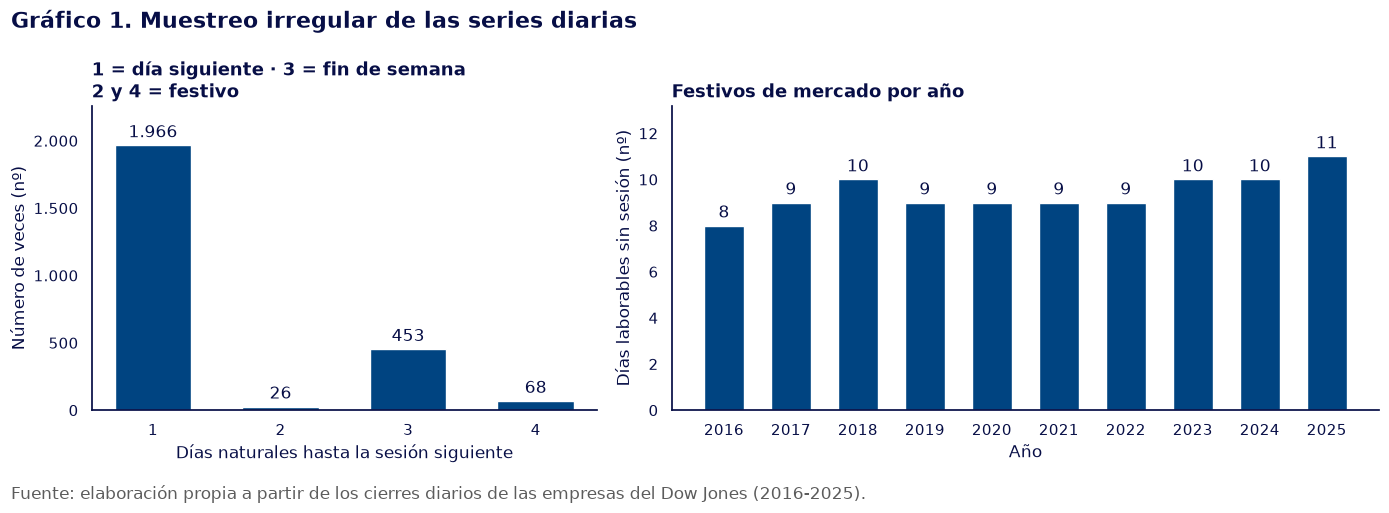

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_01_frecuencia_muestreo.png')

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
conteo = saltos.value_counts().sort_index()
barras = ax1.bar(conteo.index.astype(str), conteo.values, color=PRINCIPAL, width=0.6)
ax1.bar_label(barras, labels=[fmt_es(v) for v in conteo.values], padding=3, color=MARINO)
ax1.set_ylim(0, conteo.max() * 1.15)
ax1.set_xlabel("Días naturales hasta la sesión siguiente")
ax1.set_ylabel("Número de veces (nº)")
ax1.grid(False)
ax1.set_title("1 = día siguiente · 3 = fin de semana\n2 y 4 = festivo")

por_anio = pd.Series(festivos.year).value_counts().reindex(sorted(set(precios.index.year)), fill_value=0)
barras = ax2.bar(por_anio.index.astype(str), por_anio.values, color=PRINCIPAL, width=0.6)
ax2.bar_label(barras, labels=[fmt_es(v) for v in por_anio.values], padding=3, color=MARINO)
ax2.set_ylim(0, max(por_anio.max(), 1) * 1.2)
ax2.set_xlabel("Año")
ax2.set_ylabel("Días laborables sin sesión (nº)")
ax2.grid(False)
ax2.set_title("Festivos de mercado por año")
fig.suptitle("Gráfico 1. Muestreo irregular de las series diarias", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_01_frecuencia_muestreo", fuente=FUENTE)

In [8]:
#Serie mensual: último cierre de cada mes (estacionalidad mensual y anual)
precios_mes = precios.resample(FREC_MES).last()
log_precios_mes = np.log(precios_mes)
rent_mes = log_precios_mes.diff()
log_mercado_mes = log_mercado.resample(FREC_MES).last()
rent_mercado_mes = log_mercado_mes.diff().dropna()
print(f"Serie mensual: {len(precios_mes)} meses ({precios_mes.index[0]:%Y-%m} a {precios_mes.index[-1]:%Y-%m})")

Serie mensual: 120 meses (2016-01 a 2025-12)


**Decisión:** se trabaja en sesiones de mercado, sin rellenar fines de semana ni festivos: el mercado está cerrado y rellenarlos crearía rentabilidades nulas falsas. Para la estacionalidad mensual se usa además el último cierre de cada mes.

ANÁLISIS:

Analizando los gráficos, se puede observar que las series son diarias. A pesar de esto, se aprecian saltos de entre 2 y 4 días entre sesiones, pero esto se debe a los saltos por fines de semana y festivos. Además, si se realiza la suma de los saltos de 1,2,3 y 4 días esta da 2513 saltos en 10 años, lo que da una media de 251 sesiones por año aproximadamente.

Por otra parte, al analizar los festivos del mercado por año, se ve que todos lo años están en torno al 10, lo que son valores normales que se deben a algún cierre extraordinario del mercado.

# 2. Tendencia

Ajuste de tendencias lineal, cuadrática y exponencial.

In [9]:
def ajustar_tendencias(serie):
    """Ajusta las tendencias lineal, cuadrática y exponencial al precio. t en años desde el inicio."""
    s = serie.dropna()
    t = (s.index - s.index[0]).days.to_numpy() / 365.25
    y = s.to_numpy()
    ajustes = {
        "lineal": np.polyval(np.polyfit(t, y, 1), t),      
        "cuadratica": np.polyval(np.polyfit(t, y, 2), t),
    }
    b1, b0 = np.polyfit(t, np.log(y), 1)                          
    ajustes["exponencial"] = np.exp(b0 + b1 * t)
    total = ((y - y.mean()) ** 2).sum()
    r2 = {k: 1 - ((y - v) ** 2).sum() / total for k, v in ajustes.items()}
    return pd.DataFrame(ajustes, index=s.index), r2, np.exp(b1) - 1


tabla_tendencia = {}
for t in empresas:
    _, r2, crecimiento = ajustar_tendencias(precios[t])
    tabla_tendencia[t] = {"r2_lineal": r2["lineal"], "r2_cuadratica": r2["cuadratica"],
                          "r2_exponencial": r2["exponencial"], "mejor_tendencia": max(r2, key=r2.get),
                          "crecimiento_anual_exp": crecimiento}
tabla_tendencia = pd.DataFrame(tabla_tendencia).T
for c in ["r2_lineal", "r2_cuadratica", "r2_exponencial", "crecimiento_anual_exp"]:
    tabla_tendencia[c] = tabla_tendencia[c].astype(float)
print(tabla_tendencia.loc[orden_sector].round(3).to_string())
print("\nMejor modelo de tendencia (número de empresas):", tabla_tendencia["mejor_tendencia"].value_counts().to_dict())

      r2_lineal  r2_cuadratica  r2_exponencial mejor_tendencia  crecimiento_anual_exp
AAPL      0.936          0.947           0.873      cuadratica                  0.288
CRM       0.750          0.767           0.675      cuadratica                  0.144
CSCO      0.656          0.663           0.639      cuadratica                  0.071
IBM       0.322          0.804           0.337      cuadratica                  0.046
INTC      0.113          0.603           0.060      cuadratica                 -0.041
MSFT      0.940          0.957           0.910      cuadratica                  0.272
AXP       0.809          0.896           0.885      cuadratica                  0.167
GS        0.689          0.838           0.761      cuadratica                  0.138
JPM       0.742          0.832           0.806      cuadratica                  0.134
TRV       0.767          0.907           0.821      cuadratica                  0.089
V         0.933          0.935           0.914      cu

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_02_modelos_tendencia.png


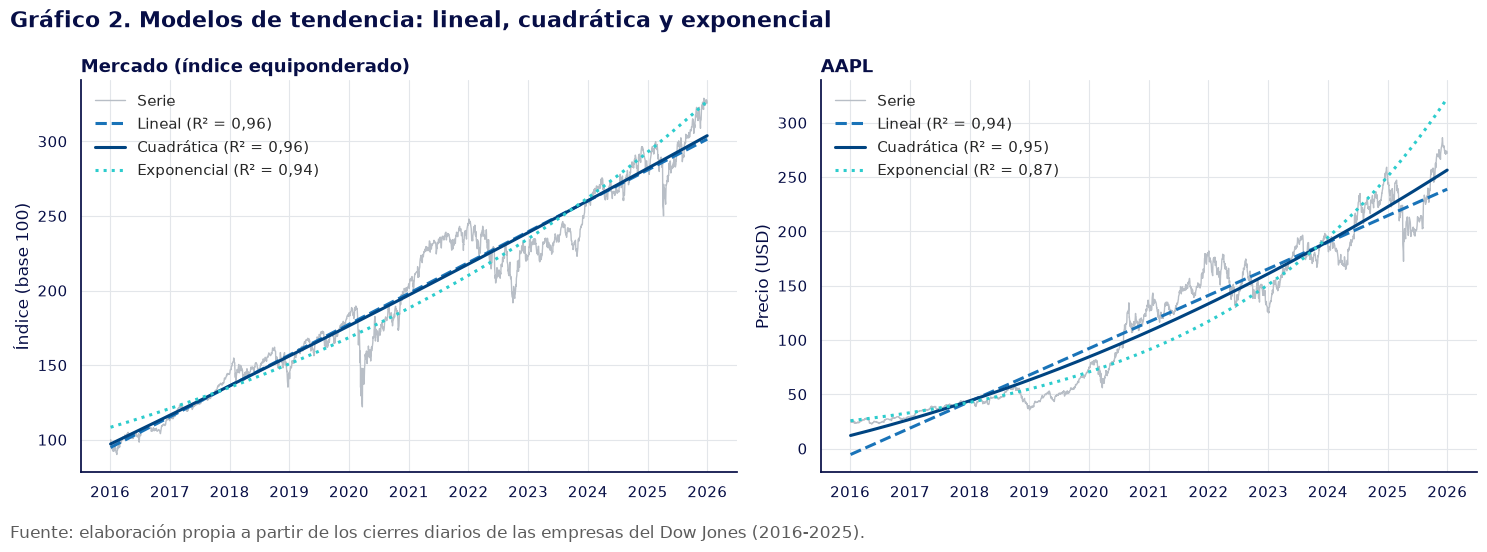

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_02_modelos_tendencia.png')

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, (nombre, serie, unidad) in zip(ejes, [("Mercado (índice equiponderado)", mercado, "Índice (base 100)"),
                                              (EMPRESA_EJEMPLO, precios[EMPRESA_EJEMPLO], "Precio (USD)")]):
    tendencias, r2, _ = ajustar_tendencias(serie)
    ax.plot(serie.dropna(), color=GRIS, lw=1, label="Serie")
    for modelo, etiqueta, col, estilo in [("lineal", "Lineal", MEDIO, "--"),
                                          ("cuadratica", "Cuadrática", PRINCIPAL, "-"),
                                          ("exponencial", "Exponencial", AGUAMARINA, ":")]:
        ax.plot(tendencias[modelo], color=col, lw=2.2, ls=estilo, label=f"{etiqueta} (R² = {fmt_es(r2[modelo], 2)})")
    eje_anios(ax)
    ax.set_ylabel(unidad)
    ax.legend(loc="upper left")
    ax.set_title(nombre)
fig.suptitle("Gráfico 2. Modelos de tendencia: lineal, cuadrática y exponencial", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_02_modelos_tendencia", fuente=FUENTE)

ANÁLISIS:
En el gráfico se observa que los 3 modelos se ajustan bastante bien a la situación del mercado. Además, sus R² son muy similares por lo que no se podría deducir cual de los modelos es más preciso por esta métrica. Sin embargo, visualizando el gráfico se observa cómo el modelo cuadrático se ajusta más al mercado, sin tener muchos picos. En cambio, se aprecia cómo el modelo exponencial sí que presenta algo más de volatilidad que los otros dos modelos.

## Eliminación de la tendencia

Comparación de tres métodos sobre el log-precio del mercado: diferenciar, restar la media móvil de 252 sesiones y restar la tendencia de Hodrick-Prescott.

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_03_eliminacion_tendencia.png


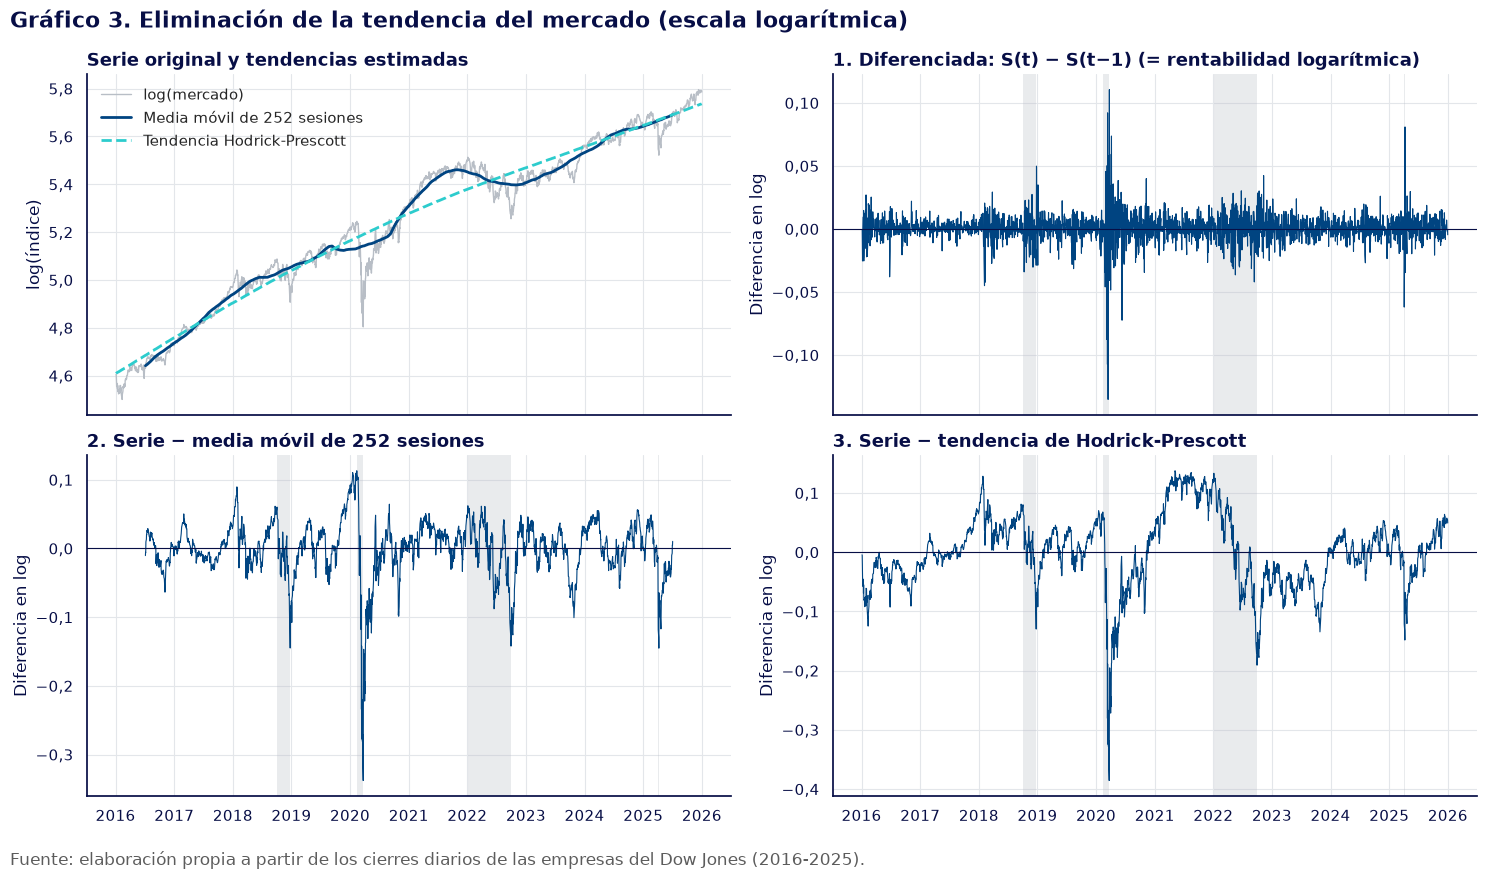

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_03_eliminacion_tendencia.png')

In [11]:
#Parámetros de esta sección
LAMBDA_HP_DIARIO = 129600 * 21 ** 4       #Hodrick-Prescott: 129.600 mensual, escalado a diario (Ravn-Uhlig)

media_movil = log_mercado.rolling(DIAS_ANIO, center=True).mean()
ciclo_hp, tendencia_hp = hpfilter(log_mercado, lamb=LAMBDA_HP_DIARIO)
ciclo_hp = pd.Series(np.asarray(ciclo_hp), index=log_mercado.index)
tendencia_hp = pd.Series(np.asarray(tendencia_hp), index=log_mercado.index)

fig, ejes = plt.subplots(2, 2, figsize=(15, 8.5), sharex=True)
ax = ejes[0, 0]
ax.plot(log_mercado, color=GRIS, lw=1, label="log(mercado)")
ax.plot(media_movil, color=PRINCIPAL, lw=2, label="Media móvil de 252 sesiones")
ax.plot(tendencia_hp, color=AGUAMARINA, lw=2, ls="--", label="Tendencia Hodrick-Prescott")
ax.set_ylabel("log(índice)")
ax.legend(loc="upper left")
ax.set_title("Serie original y tendencias estimadas")

for ax, serie, titulo in [
    (ejes[0, 1], rent_mercado, "1. Diferenciada: S(t) − S(t−1) (= rentabilidad logarítmica)"),
    (ejes[1, 0], log_mercado - media_movil, "2. Serie − media móvil de 252 sesiones"),
    (ejes[1, 1], ciclo_hp, "3. Serie − tendencia de Hodrick-Prescott"),
]:
    sombrear_episodios(ax)
    ax.plot(serie, color=PRINCIPAL, lw=0.8)
    ax.axhline(0, color=MARINO, lw=0.8)
    ax.set_ylabel("Diferencia en log")
    ax.set_title(titulo)
for ax in ejes.flat:
    eje_anios(ax)
fig.suptitle("Gráfico 3. Eliminación de la tendencia del mercado (escala logarítmica)", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_03_eliminacion_tendencia", fuente=FUENTE)

ANÁLISIS:

El gráfico de arriba a la izquierda muestra la tendencia que estima cada método. La media móvil sigue de cerca a la serie, por lo que también recoge los movimientos de medio plazo y pierde medio año de datos en cada extremo. La tendencia de Hodrick-Prescott es mucho más suave y solo recoge la dirección de largo plazo.

En la serie diferenciada, la serie oscila alrededor de 0 durante todo el periodo. En 2020 y 2025 las oscilaciones son más amplias, pero siguen centradas en 0: es un cambio de varianza, no de nivel, que se estudia en la sección de heterocedasticidad. En la serie menos la media móvil y en la serie menos la tendencia HP se ven temporadas largas por encima o por debajo de 0. En la media móvil, se ve cómo hay temporadas largas que están por debajo de 0 en 2020 y 2022. En cambio, en el filtro HP entre 2018 y 2019 se encuentra por encima de 0 una temporada larga y también entre 2021 y 2022. Todo ello indica que queda estructura de medio plazo (ciclo).

Por tanto, el método que mejor elimina la tendencia es la diferenciación: deja la media estable en todo el periodo, solo pierde el primer dato y no usa información futura.

# 3. Descomposición aditiva o multiplicativa

Correlación de Spearman entre el nivel (media móvil de 12 meses) y la amplitud de las fluctuaciones, en precio y en logaritmo.

Antes de descomponer la serie en tendencia, estacionalidad y residuo (sección 4), hay que decidir qué tipo de descomposición es la adecuada.

In [12]:
def amplitud_y_nivel(serie_mensual):
    s = serie_mensual.dropna()
    nivel = s.rolling(12, center=True).mean()
    amplitud = (s - nivel).abs().rolling(12, center=True).mean()
    datos = pd.DataFrame({"nivel": nivel, "amplitud": amplitud}).dropna()
    return datos, stats.spearmanr(datos["nivel"], datos["amplitud"]).correlation


tabla_descomposicion = {}
for t in empresas:
    _, rho_precio = amplitud_y_nivel(precios_mes[t])
    _, rho_log = amplitud_y_nivel(log_precios_mes[t])
    #En la escala logarítmica la amplitud es relativa (%), así que se compara con la amplitud en precio
    tabla_descomposicion[t] = {"rho_amplitud_nivel_precio": rho_precio, "rho_amplitud_nivel_log": rho_log}
tabla_descomposicion = pd.DataFrame(tabla_descomposicion).T
tabla_descomposicion["descomposicion"] = np.where(
    tabla_descomposicion["rho_amplitud_nivel_precio"] > 0.3, "multiplicativa", "aditiva")
print(tabla_descomposicion.loc[orden_sector].round(2).to_string())
print("\nNúmero de empresas:", tabla_descomposicion["descomposicion"].value_counts().to_dict())

      rho_amplitud_nivel_precio  rho_amplitud_nivel_log  descomposicion
AAPL                       0.95                    0.06  multiplicativa
CRM                        0.91                    0.76  multiplicativa
CSCO                       0.15                   -0.37         aditiva
IBM                        0.67                    0.27  multiplicativa
INTC                       0.29                   -0.31         aditiva
MSFT                       0.89                    0.56  multiplicativa
AXP                        0.90                    0.46  multiplicativa
GS                         0.60                   -0.46  multiplicativa
JPM                        0.44                   -0.11  multiplicativa
TRV                        0.69                    0.22  multiplicativa
V                          0.83                    0.33  multiplicativa
AMGN                       0.84                    0.54  multiplicativa
JNJ                        0.47                   -0.04  multipl

ANÁLISIS:

Al pasar a logaritmo, el rho disminuye en todas las empresas. Sin embargo, lo importante no es que disminuya, sino que se acerque a 0. En la mayoría de empresas así ocurre, lo que confirma que el logaritmo estabiliza la amplitud de las fluctuaciones (por ejemplo, AAPL pasa de 0,95 a 0,06). En cambio, en CSCO e INTC el logaritmo aleja el rho de 0 y lo vuelve negativo. Estas empresas ya eran aditivas en precio, por lo que la amplitud no dependía del nivel y el logaritmo genera una relación contraria. Aun así, se trabaja con logaritmos en todas las empresas para que las rentabilidades sean comparables entre sí.

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_04_aditiva_multiplicativa.png


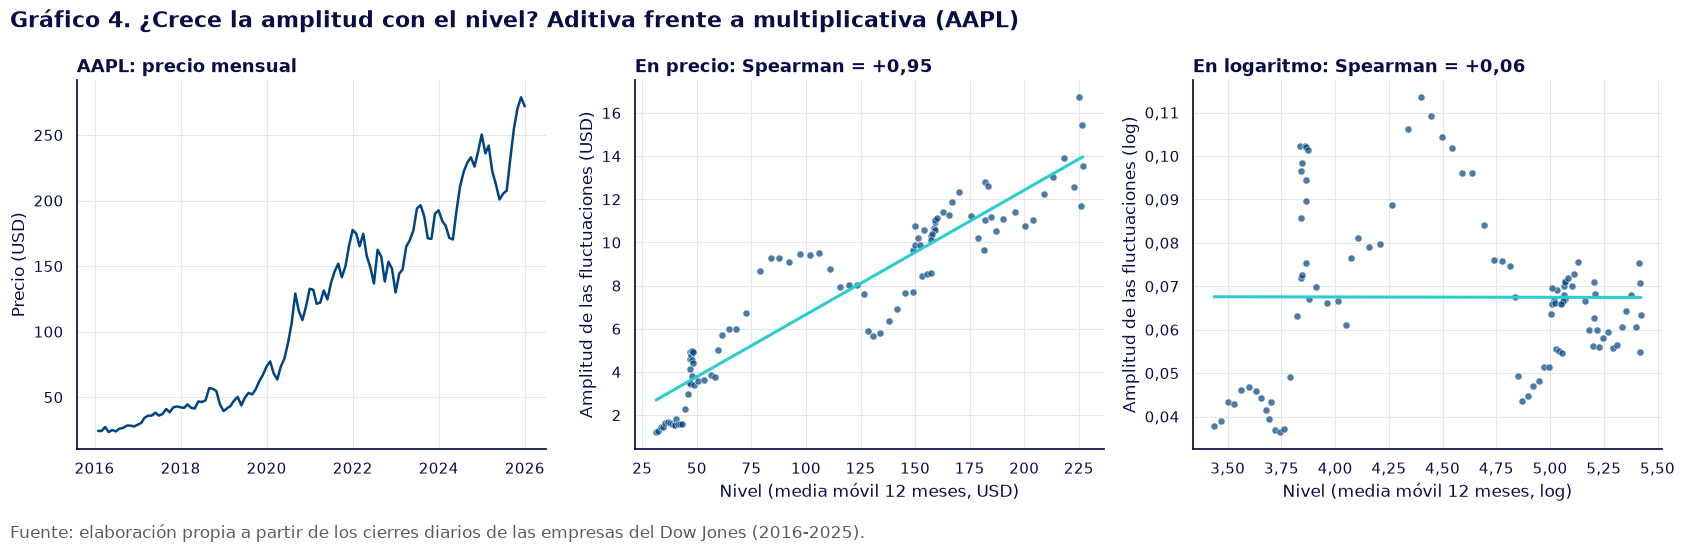

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_04_aditiva_multiplicativa.png')

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 5.2))
datos_precio, rho_precio = amplitud_y_nivel(precios_mes[EMPRESA_EJEMPLO])
datos_log, rho_log = amplitud_y_nivel(log_precios_mes[EMPRESA_EJEMPLO])

ax = ejes[0]
ax.plot(precios_mes[EMPRESA_EJEMPLO], color=PRINCIPAL, lw=1.8)
eje_anios(ax)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.set_ylabel("Precio (USD)")
ax.set_title(f"{EMPRESA_EJEMPLO}: precio mensual")

for ax, datos, rho, titulo, unidad in [
        (ejes[1], datos_precio, rho_precio, "En precio", "USD"),
        (ejes[2], datos_log, rho_log, "En logaritmo", "log")]:
    ax.scatter(datos["nivel"], datos["amplitud"], s=26, color=PRINCIPAL, alpha=0.7, edgecolor=BLANCO, linewidth=0.5)
    pendiente, corte = np.polyfit(datos["nivel"], datos["amplitud"], 1)
    x = np.linspace(datos["nivel"].min(), datos["nivel"].max(), 50)
    ax.plot(x, corte + pendiente * x, color=AGUAMARINA, lw=2.2)
    ax.set_xlabel(f"Nivel (media móvil 12 meses, {unidad})")
    ax.set_ylabel(f"Amplitud de las fluctuaciones ({unidad})")
    ax.set_title(f"{titulo}: Spearman = {fmt_signo(rho, 2)}")
fig.suptitle(f"Gráfico 4. ¿Crece la amplitud con el nivel? Aditiva frente a multiplicativa ({EMPRESA_EJEMPLO})",
             x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_04_aditiva_multiplicativa", fuente=FUENTE)

ANÁLISIS:

Analizando los gráficos de la correlación de Spearman se puede ver cómo en el precio tiene una tendencia ascendente, cuanto mayor es el nivel del precio, mayor es la amplitud de sus fluctuaciones. Por ejemplo, cuando el nivel se encuentra en 30$ la amplitud de las fluctuaciones es de aproximadamente 2$, en cambio, cuando el nivel alcanza los 200$ la amplitud es de 11$. Es decir, el nivel se multiplica por unas 7 veces y la amplitud por unos 5,5. Por ello, la amplitud crece más o menos de manera proporcional al nivel. Por último, la correlación de Spearman es 0.95, por lo que la serie es multiplicativa.

Por otra parte, si se analiza la correlación de Spearman en los logaritmos, se aprecia cómo la tendencia es plana. Por lo tanto, se deduce que la relación entre la amplitud y el nivel desaparece. Además de eso, la correlación de Spearman corrobora esta deducción ya que baja hasta el 0.06. La amplitud relativa se mantiene aproximadamente entre un 4% y un 11% en todos los niveles. 

# 4. Estacionalidad y componente cíclica

Como las series son multiplicativas (sección 3), se trabaja con el logaritmo. Los efectos de calendario se contrastan con el test de Kruskal-Wallis, porque las rentabilidades no son normales.

In [14]:
NOMBRES_DIA = ["Lun", "Mar", "Mié", "Jue", "Vie"]
NOMBRES_MES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]


def p_kruskal(serie, grupos):
    s = serie.dropna()
    muestras = [g.to_numpy() for _, g in s.groupby(grupos.reindex(s.index)) if len(g) > 2]
    return stats.kruskal(*muestras).pvalue


def autocorrelacion(serie, retardo):
    s = serie.dropna()
    return s.autocorr(retardo) if len(s) > retardo + 2 else np.nan


tabla_estacional = pd.DataFrame({
    "p_dia_semana": {t: p_kruskal(rent_log[t], rent_log.index.to_series().dt.dayofweek) for t in empresas},
    "p_mes": {t: p_kruskal(rent_mes[t], rent_mes.index.to_series().dt.month) for t in empresas},
    "acf_mensual_12": {t: autocorrelacion(rent_mes[t], 12) for t in empresas},
})
tabla_estacional.loc["MERCADO"] = [
    p_kruskal(rent_mercado, rent_mercado.index.to_series().dt.dayofweek),
    p_kruskal(rent_mercado_mes, rent_mercado_mes.index.to_series().dt.month),
    autocorrelacion(rent_mercado_mes, 12),
]
print(tabla_estacional.loc[orden_sector + ["MERCADO"]].round(3).to_string())
print(f"\nEmpresas con efecto día de la semana significativo: {(tabla_estacional['p_dia_semana'] < ALFA).sum() - (tabla_estacional.loc['MERCADO', 'p_dia_semana'] < ALFA)} de {N}"
      f" | con efecto mes: {(tabla_estacional['p_mes'] < ALFA).sum() - (tabla_estacional.loc['MERCADO', 'p_mes'] < ALFA)} de {N}"
      f"\n(con α = {ALFA:.0%}, por puro azar se esperan unas {ALFA * N:.1f} empresas significativas en cada test)")

         p_dia_semana  p_mes  acf_mensual_12
AAPL            0.028  0.552           0.050
CRM             0.764  0.145           0.056
CSCO            0.101  0.797           0.008
IBM             0.114  0.179           0.095
INTC            0.463  0.312          -0.048
MSFT            0.866  0.184           0.082
AXP             0.851  0.267          -0.177
GS              0.119  0.114          -0.036
JPM             0.870  0.291          -0.112
TRV             0.690  0.331          -0.098
V               0.544  0.166          -0.063
AMGN            0.037  0.304          -0.106
JNJ             0.465  0.768           0.010
MRK             0.308  0.428          -0.085
UNH             0.543  0.138           0.133
BA              0.897  0.259           0.159
CAT             0.866  0.357          -0.177
MMM             0.815  0.472          -0.032
HD              0.132  0.109          -0.005
MCD             0.506  0.088          -0.065
NKE             0.897  0.282           0.031
KO        

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_05_estacionalidad_calendario_fourier.png


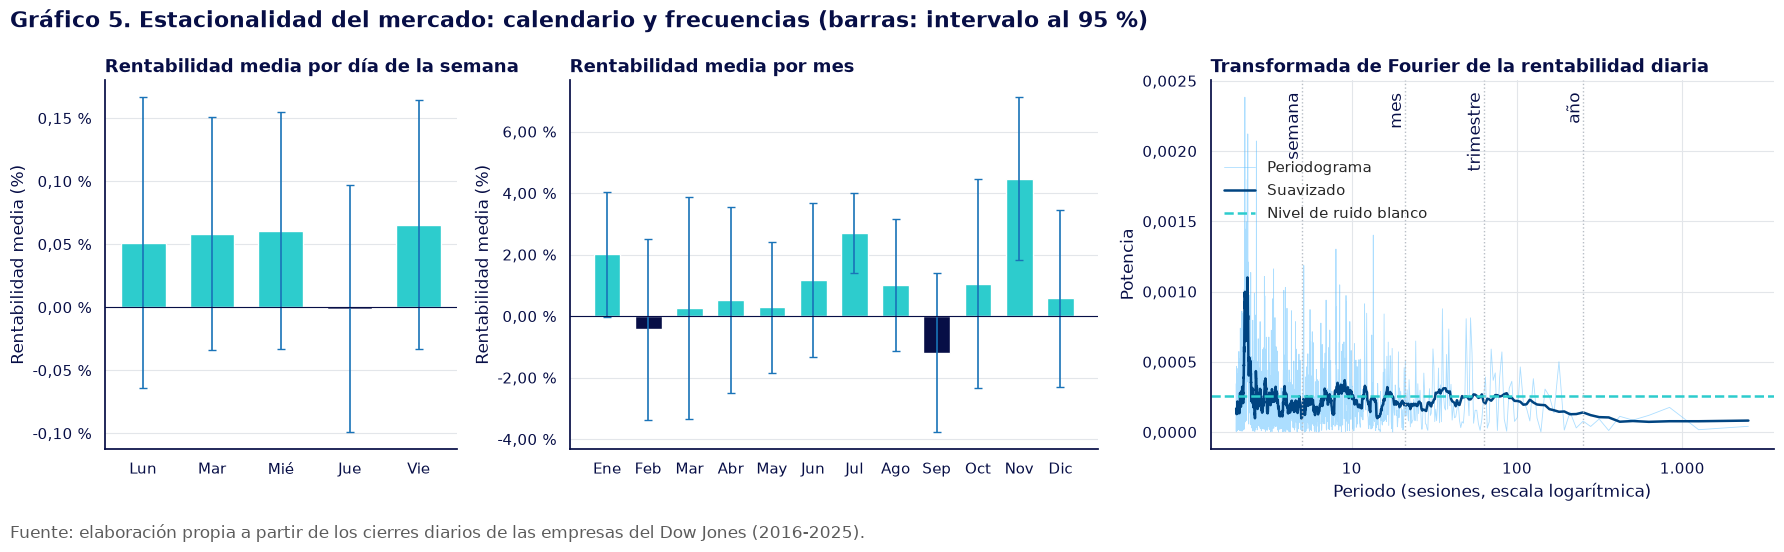

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_05_estacionalidad_calendario_fourier.png')

In [15]:
def media_con_intervalo(serie, grupos):
    tabla = serie.groupby(grupos).agg(["mean", "std", "count"])
    return tabla["mean"], 1.96 * tabla["std"] / np.sqrt(tabla["count"])


frecuencias, potencia = signal.periodogram(rent_mercado.to_numpy(), detrend="constant")
frecuencias, potencia = frecuencias[1:], potencia[1:]
potencia_suave = pd.Series(potencia).rolling(15, center=True, min_periods=1).mean().to_numpy()

fig, ejes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1.5, 1.6]})
for ax, (serie, grupos, nombres, titulo) in zip(ejes[:2], [
        (rent_mercado, rent_mercado.index.dayofweek, NOMBRES_DIA, "Rentabilidad media por día de la semana"),
        (rent_mercado_mes, rent_mercado_mes.index.month, NOMBRES_MES, "Rentabilidad media por mes")]):
    media, intervalo = media_con_intervalo(serie, grupos)
    ax.bar(range(len(media)), media, yerr=intervalo, color=np.where(media >= 0, AGUAMARINA, MARINO), width=0.65,
           error_kw={"ecolor": MEDIO, "elinewidth": 1.2, "capsize": 3})
    ax.set_xticks(range(len(media)), [nombres[i] for i in range(len(media))])
    ax.axhline(0, color=MARINO, lw=0.8)
    formato_eje_pct(ax, decimales=2)
    ax.set_ylabel("Rentabilidad media (%)")
    ax.grid(axis="x", visible=False)
    ax.set_title(titulo)

ax = ejes[2]
ax.plot(1 / frecuencias, potencia, color=CIELO, lw=0.6, alpha=0.5, label="Periodograma")
ax.plot(1 / frecuencias, potencia_suave, color=PRINCIPAL, lw=1.8, label="Suavizado")
ax.axhline(potencia.mean(), color=AGUAMARINA, lw=1.8, ls="--", label="Nivel de ruido blanco")
for periodo, etiqueta in [(5, "semana"), (21, "mes"), (63, "trimestre"), (252, "año")]:
    ax.axvline(periodo, color=GRIS, lw=1, ls=":")
    ax.text(periodo, 0.98, f"{etiqueta} ", transform=ax.get_xaxis_transform(), color=MARINO,
            va="top", ha="right", rotation=90)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt_es(v)))
ax.set_xlabel("Periodo (sesiones, escala logarítmica)")
ax.set_ylabel("Potencia")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.82))
ax.set_title("Transformada de Fourier de la rentabilidad diaria")
fig.suptitle("Gráfico 5. Estacionalidad del mercado: calendario y frecuencias (barras: intervalo al 95 %)",
             x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_05_estacionalidad_calendario_fourier", fuente=FUENTE)

ANÁLISIS:

En la rentabilidad media por día de la semana, todas las barras son positivas y bastante similares, salvo el jueves, que está prácticamente en 0. Sin embargo, todos sus intervalos de confianza cruzan el 0 y se solapan entre sí, por lo que ningún día se distingue de los demás.

En la rentabilidad media mensual, febrero y septiembre son negativos y noviembre tiene la media más alta, llegando a un 4 %. Sin embargo, cada barra mensual es la media de solo 10 años. Todos los intervalos cruzan el 0 salvo los de julio y noviembre, aunque estos se solapan con los de la mayoría de meses, por lo que no se puede afirmar que sean distintos del resto. Además, al comparar 12 meses es esperable que alguno no cruce el 0 por azar.

## Descomposición estacional

Log-precio mensual del mercado con periodo 12, y fuerza de la tendencia (F_T) y de la estacionalidad (F_S) de Hyndman para cada empresa.

       fuerza_tendencia  fuerza_estacionalidad
count            27.000                 27.000
mean              0.938                  0.118
std               0.048                  0.054
min               0.797                  0.026
25%               0.915                  0.072
50%               0.952                  0.107
75%               0.972                  0.144
max               0.993                  0.242


Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_06_descomposicion_estacional.png


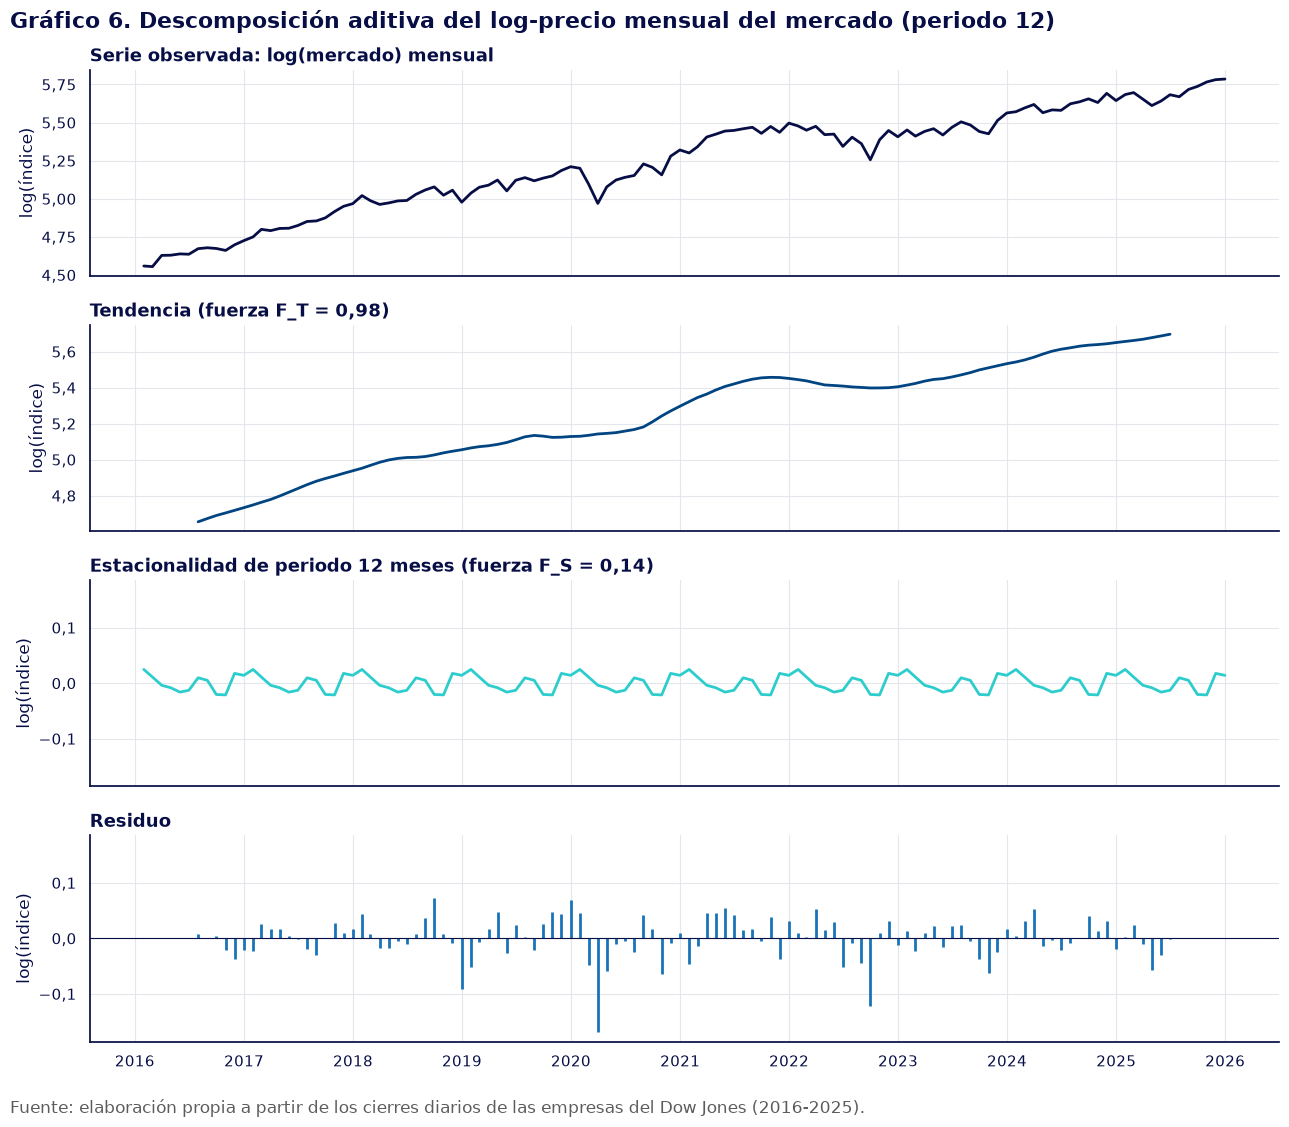

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_06_descomposicion_estacional.png')

In [16]:
def fuerzas_componentes(serie_mensual):
    s = serie_mensual.dropna()
    d = seasonal_decompose(s, model="additive", period=12)
    datos = pd.DataFrame({"T": d.trend, "S": d.seasonal, "R": d.resid}).dropna()
    f_t = max(0.0, 1 - datos["R"].var() / (datos["T"] + datos["R"]).var())
    f_s = max(0.0, 1 - datos["R"].var() / (datos["S"] + datos["R"]).var())
    return d, f_t, f_s


tabla_estacional["fuerza_tendencia"] = np.nan
tabla_estacional["fuerza_estacionalidad"] = np.nan
for t in empresas:
    _, f_t, f_s = fuerzas_componentes(log_precios_mes[t])
    tabla_estacional.loc[t, ["fuerza_tendencia", "fuerza_estacionalidad"]] = [f_t, f_s]
descomp_mercado, f_t, f_s = fuerzas_componentes(log_mercado_mes)
tabla_estacional.loc["MERCADO", ["fuerza_tendencia", "fuerza_estacionalidad"]] = [f_t, f_s]
print(tabla_estacional[["fuerza_tendencia", "fuerza_estacionalidad"]].describe().round(3).to_string())

fig, ejes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
for ax, (serie, titulo, col) in zip(ejes, [
        (descomp_mercado.observed, "Serie observada: log(mercado) mensual", MARINO),
        (descomp_mercado.trend, f"Tendencia (fuerza F_T = {fmt_es(f_t, 2)})", PRINCIPAL),
        (descomp_mercado.seasonal, f"Estacionalidad de periodo 12 meses (fuerza F_S = {fmt_es(f_s, 2)})", AGUAMARINA),
        (descomp_mercado.resid, "Residuo", MEDIO)]):
    if titulo == "Residuo":
        ax.vlines(serie.index, 0, serie, color=col, lw=2)
        ax.axhline(0, color=MARINO, lw=0.8)
    else:
        ax.plot(serie, color=col, lw=2)
    ax.set_ylabel("log(índice)")
    ax.set_title(titulo)
eje_anios(ejes[-1])
#Misma escala vertical en estacionalidad y residuo, para comparar su tamaño
limite = np.nanmax(np.abs(np.concatenate([descomp_mercado.seasonal, descomp_mercado.resid.dropna()]))) * 1.1
for ax in ejes[2:]:
    ax.set_ylim(-limite, limite)
fig.suptitle("Gráfico 6. Descomposición aditiva del log-precio mensual del mercado (periodo 12)", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_06_descomposicion_estacional", fuente=FUENTE)

ANÁLISIS:

La fuerza de la tendencia es F_T = 0,98, lo que confirma la tendencia muy marcada que ya se eliminó por diferenciación en la sección anterior. La componente estacional tiene un tamaño similar o menor que el residuo, y el residuo tiene además movimientos mucho mayores en episodios concretos (2020, 2022). Por tanto, la estacionalidad no se distingue del ruido, lo que concuerda con su fuerza baja (F_S = 0,14). 

## Componente cíclica

Filtros de Hodrick-Prescott y de Baxter-King (periodos de 1 a 5 años).

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_07_componente_ciclica.png


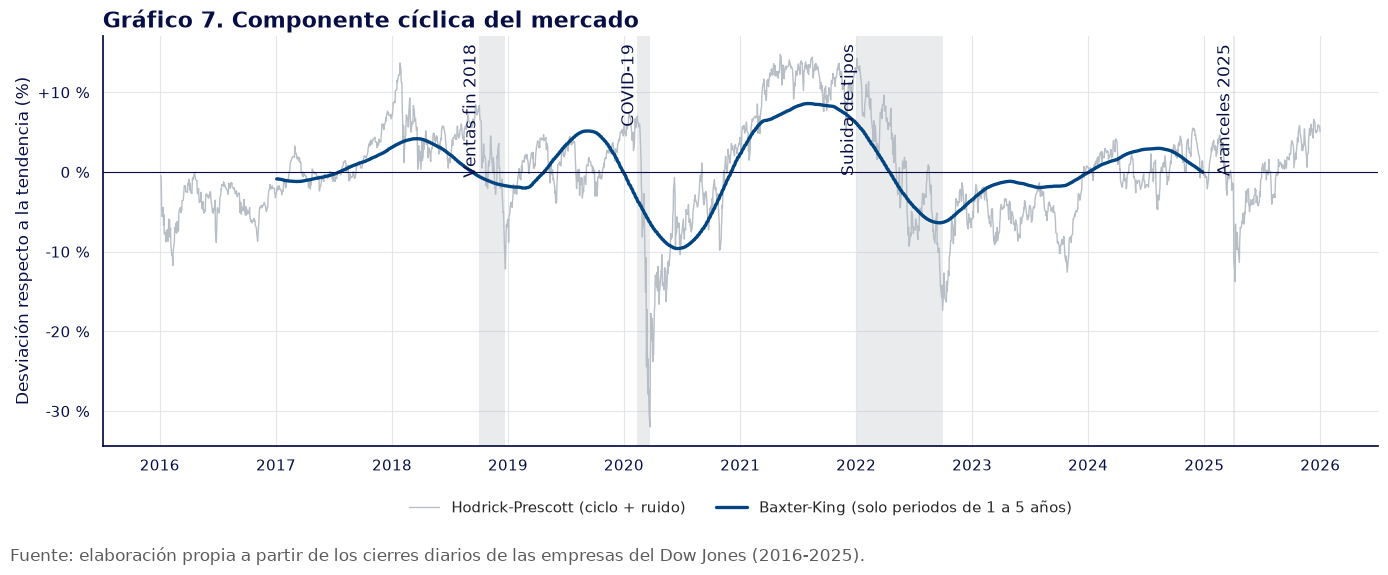

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_07_componente_ciclica.png')

In [17]:
#Parámetros de esta sección
CICLO_MIN, CICLO_MAX = 252, 5 * 252       #Baxter-King: oscilaciones de 1 a 5 años (componente cíclica)

ciclo_bk = bkfilter(log_mercado, low=CICLO_MIN, high=CICLO_MAX, K=DIAS_ANIO)
ciclo_bk = pd.Series(np.asarray(ciclo_bk).ravel(), index=log_mercado.index[DIAS_ANIO:len(log_mercado) - DIAS_ANIO])

fig, ax = plt.subplots(figsize=(14, 5.5))
sombrear_episodios(ax, etiquetas=True)
# exp(x) − 1 pasa la desviación en logaritmo a porcentaje sobre la tendencia
ax.plot(np.expm1(ciclo_hp), color=GRIS, lw=1, label="Hodrick-Prescott (ciclo + ruido)")
ax.plot(np.expm1(ciclo_bk), color=PRINCIPAL, lw=2.4, label="Baxter-King (solo periodos de 1 a 5 años)")
ax.axhline(0, color=MARINO, lw=0.8)
eje_anios(ax)
formato_eje_pct(ax, signo=True)
ax.set_ylabel("Desviación respecto a la tendencia (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set_title("Gráfico 7. Componente cíclica del mercado")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_07_componente_ciclica", fuente=FUENTE)

ANÁLISIS:

El filtro de Hodrick-Prescott muestra la desviación respecto a la tendencia incluyendo el ruido de corto plazo, con caídas bruscas en los episodios de crisis (hasta un −30 % en el COVID). El filtro de Baxter-King  aísla las oscilaciones de entre 1 y 5 años y pierde un año en cada extremo de la serie.

Se observa una componente cíclica: el mercado alterna periodos por encima de la tendencia (2018, 2019, 2021 y 2024) y por debajo (finales de 2018, 2020, 2022 y 2023). Sin embargo, este ciclo no es periódico: la distancia entre máximos varía entre 1,5 y 3 años y la amplitud cambia mucho de un ciclo a otro (del −2 % en 2018 al −10 % en 2020). Los mínimos coinciden con los episodios de crisis (ventas de 2018, COVID y subida de tipos de 2022) y los máximos con las recuperaciones posteriores, por lo que el ciclo responde a acontecimientos concretos y no a un patrón que se repita.

Además, al ser un filtro centrado, Baxter-King utiliza información futura (empieza a bajar antes del COVID) y suaviza los extremos, por lo que sirve para describir el ciclo pero no para predecir. Como el ciclo no es periódico, no se puede eliminar como una estacionalidad; la diferenciación aplicada en la sección de tendencia ya elimina estas oscilaciones lentas.

# 5. Residuo y puntos de impacto

Separación de señal y ruido con la transformada de Fourier: se conservan los periodos de más de un trimestre (63 sesiones).

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_08_senal_ruido_fourier.png


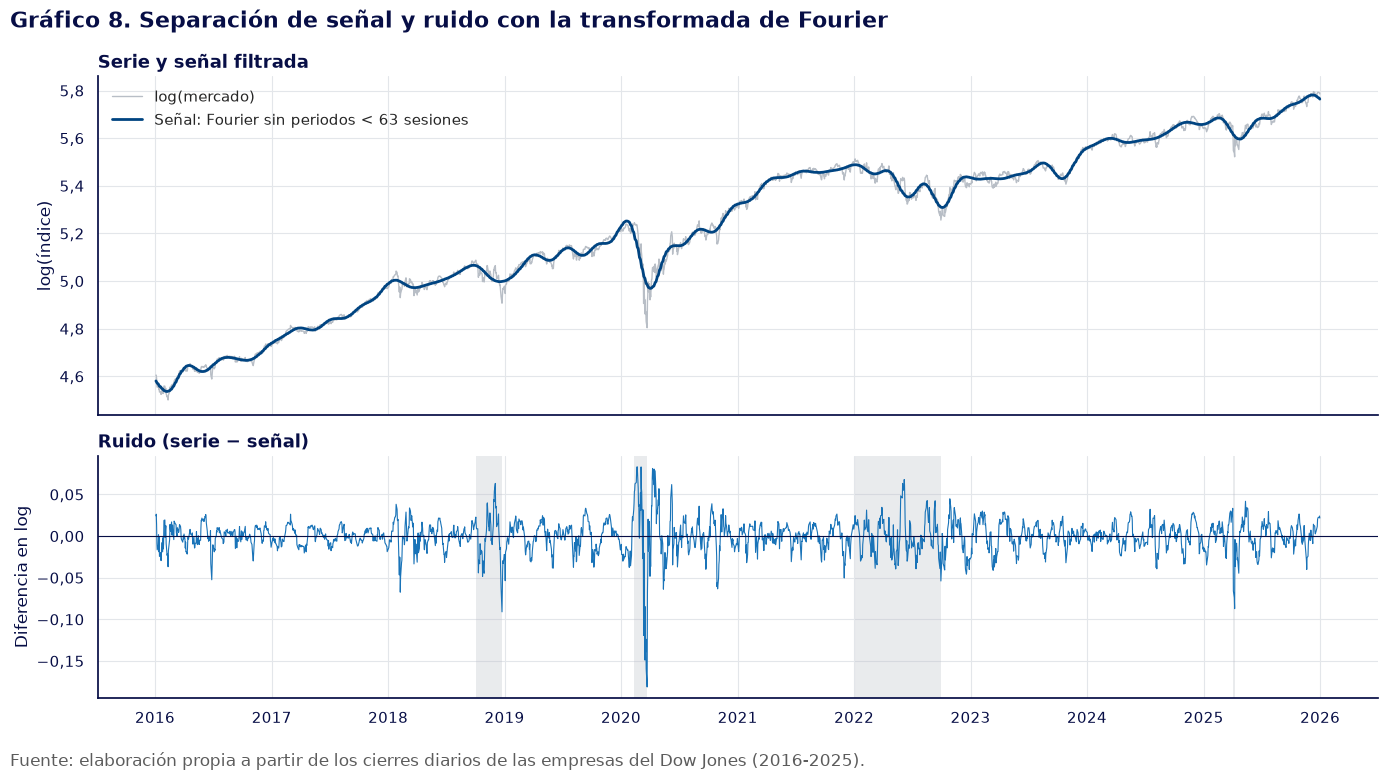

Varianza del ruido / varianza de la serie sin tendencia: 5,7 %


In [18]:
#Parámetros de esta sección
VENTANA_LARGA = 63               # ~1 trimestre de sesiones

y = log_mercado.to_numpy()
#Se quita la recta que une el primer y el último valor: así la serie empieza y acaba en 0 y la FFT
#(que supone una serie periódica) no crea oscilaciones artificiales en los extremos
tendencia_lineal = np.linspace(y[0], y[-1], len(y))
espectro = np.fft.rfft(y - tendencia_lineal)
frecuencias_fft = np.fft.rfftfreq(len(y), d=1)            #Ciclos por sesión
mascara = frecuencias_fft <= 1 / VENTANA_LARGA            #Se conservan periodos >= 63 sesiones
senal = pd.Series(np.fft.irfft(espectro * mascara, n=len(y)) + tendencia_lineal, index=log_mercado.index)
ruido = log_mercado - senal

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
ax1.plot(log_mercado, color=GRIS, lw=1, label="log(mercado)")
ax1.plot(senal, color=PRINCIPAL, lw=2, label=f"Señal: Fourier sin periodos < {VENTANA_LARGA} sesiones")
ax1.set_ylabel("log(índice)")
ax1.legend(loc="upper left")
ax1.set_title("Serie y señal filtrada")
sombrear_episodios(ax2)
ax2.plot(ruido, color=MEDIO, lw=0.8)
ax2.axhline(0, color=MARINO, lw=0.8)
ax2.set_ylabel("Diferencia en log")
ax2.set_title("Ruido (serie − señal)")
eje_anios(ax2)
fig.suptitle("Gráfico 8. Separación de señal y ruido con la transformada de Fourier", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_08_senal_ruido_fourier", fuente=FUENTE)
print(f"Varianza del ruido / varianza de la serie sin tendencia: {pct_es(ruido.var() / (y - tendencia_lineal).var(), 1)}")

ANÁLISIS:

En el gráfico superior, se puede apreciar cómo la señal sigue de muy cerca al mercado. Asimismo, cuando hay caídas bruscas del mercado la señal no la sigue ya que se trata de un desplome a muy corto plazo.  Por lo tanto, la señal recoge toda la información relevante y solo quita vaivenes a corto plazo.

En el gráfico inferior, se visualiza el ruido y cómo a lo largo de la serie oscila siempre en torno al 0. A pesar de eso, también existen fluctuaciones más grandes en periodos específicos de tiempo; como por ejemplo: en 2019 y en 2020 debido a la pandemia del COVID-19.

Además, la varianza del ruido es muy baja (5,7 %), por lo que refuerza la teoría de que la señal sigue muy de cerca al mercado, es decir, la variación del precio se encuentra en los movimientos lentos (tendencia y ciclo), y el ruido se considera muy poco a una escala de 10 años.

## Detección de puntos de impacto

Un día es punto de impacto si |z| > 5, con z = (r − mediana) / (1,4826 · MAD) de las 63 sesiones anteriores. Si lo es para al menos el 30 % de las empresas, es un impacto de mercado.

In [19]:
#Parámetros de esta sección
UMBRAL_IMPACTO = 5                #|z robusto| a partir del cual un día es punto de impacto
CUOTA_IMPACTO_MERCADO = 0.30      #si >= 30 % de las empresas tienen impacto el mismo día, es de mercado

def z_robusto(r, ventana=VENTANA_LARGA):
    """z robusto respecto a las `ventana` sesiones anteriores (sin usar el propio día)."""
    pasado = r.shift(1)
    mediana = pasado.rolling(ventana, min_periods=ventana // 2).median()
    mad = pasado.rolling(ventana, min_periods=ventana // 2).apply(
        lambda x: np.median(np.abs(x - np.median(x))), raw=True)
    return (r - mediana) / (1.4826 * mad)


z_empresas = rent_log.apply(z_robusto)
impacto = z_empresas.abs() > UMBRAL_IMPACTO
cuota_dia = impacto.sum(axis=1) / rent_log.notna().sum(axis=1)
dia_mercado = cuota_dia >= CUOTA_IMPACTO_MERCADO
impacto_mercado = impacto.mul(dia_mercado, axis=0)
impacto_especifico = impacto & ~impacto_mercado

z_mercado = z_robusto(rent_mercado)
impacto_indice = z_mercado.abs() > UMBRAL_IMPACTO

tabla_impactos = pd.DataFrame({
    "impactos_total": impacto.sum(),
    "impactos_mercado": impacto_mercado.sum(),
    "impactos_especificos": impacto_especifico.sum(),
    "pct_dias": impacto.sum() / rent_log.notna().sum(),
    "fecha_mayor_impacto": rent_log.where(impacto).abs().apply(
        lambda c: c.idxmax().date() if c.notna().any() else None),
})
print(tabla_impactos.loc[orden_sector].to_string())
print(f"\nDías de impacto de mercado: {int(dia_mercado.sum())}")
print(cuota_dia[dia_mercado].sort_values(ascending=False).head(10).map("{:.0%}".format).to_string())

        impactos_total  impactos_mercado  impactos_especificos  pct_dias fecha_mayor_impacto
symbol                                                                                      
AAPL                22                 6                    16  0.008754          2025-04-09
CRM                 19                 3                    16  0.007561          2020-08-26
CSCO                27                 9                    18  0.010744          2022-05-19
IBM                 31                 8                    23  0.012336          2020-03-12
INTC                23                 8                    15  0.009152          2024-08-02
MSFT                22                 7                    15  0.008754          2020-03-16
AXP                 33                13                    20  0.013132          2020-03-24
GS                  18                10                     8  0.007163          2020-03-13
JPM                 32                13                    19  0.0127

ANÁLISIS:

Se ha realizado un análisis de los puntos de impacto de cada empresa, es decir, un día en que la rentabilidad de la empresa se aleja mucho de la de los 3 meses anteriores. El porcentaje de días con impacto es bajo en todas las empresas (el más alto lo tiene JNJ, 1,4 %).

Un porcentaje muy alto de los impactos de las empresas son específicos, es decir, menos del 30% de las empresas tuvieron un impacto en esa fecha. Por ejemplo, de los 22 impactos de AAPL, 16 son específicos y tan solo 6 son del mercado. Por lo tanto, se concluye que la mayoría de los impactos de las empresas se deben a sorpresas de las propias empresas o de un sector en específico.

Por último, los puntos de impacto no se eliminan, ya que son movimientos reales del precio y no errores de los datos. Se marcan en la columna `impacto` de la serie procesada para poder tenerlos en cuenta en los modelos posteriores.


Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_09_puntos_impacto.png


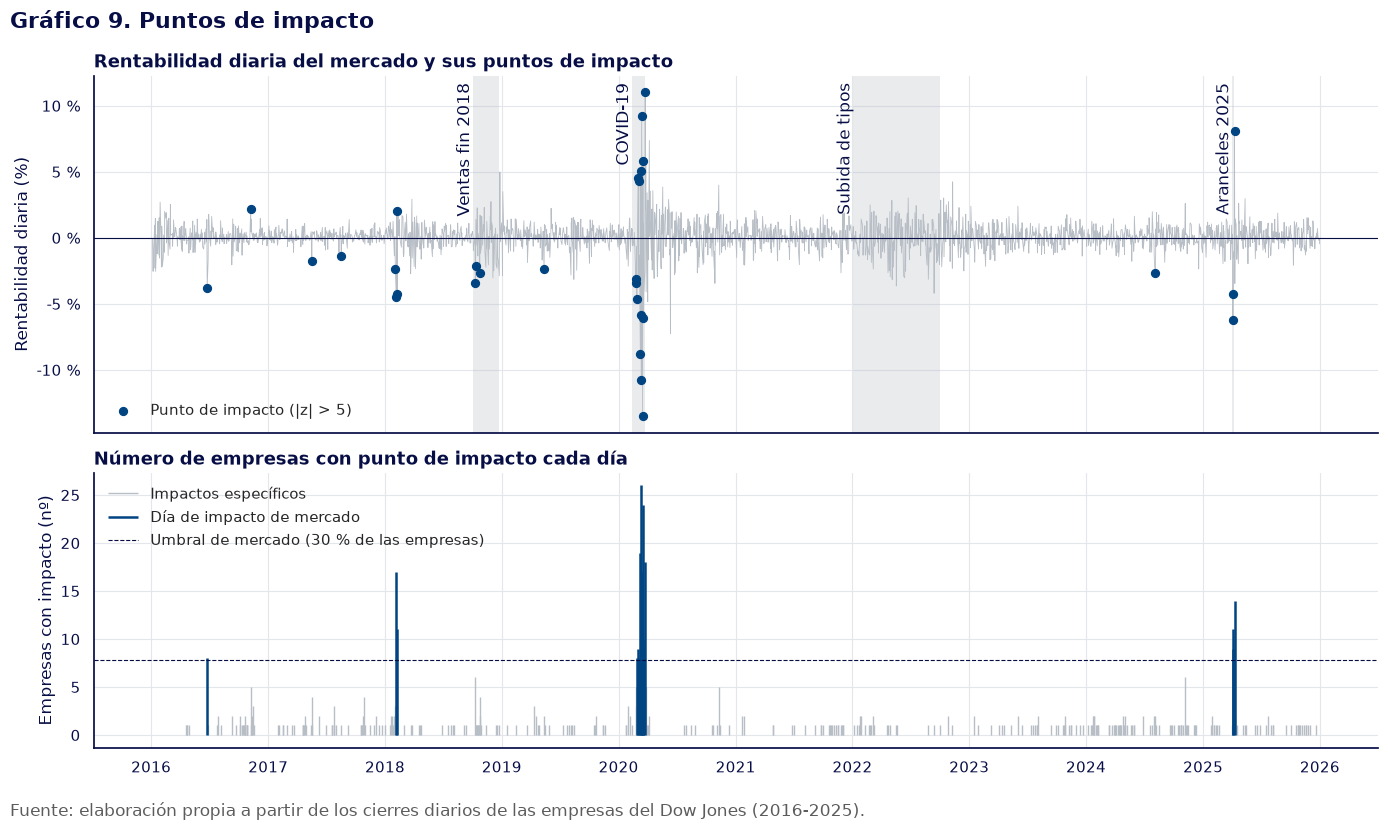

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_09_puntos_impacto.png')

In [20]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
sombrear_episodios(ax1, etiquetas=True)
ax1.plot(rent_mercado, color=GRIS, lw=0.6)
picos = rent_mercado[impacto_indice.reindex(rent_mercado.index, fill_value=False)]
ax1.scatter(picos.index, picos, s=32, color=PRINCIPAL, zorder=3, label=f"Punto de impacto (|z| > {UMBRAL_IMPACTO})")
ax1.axhline(0, color=MARINO, lw=0.8)
formato_eje_pct(ax1)
ax1.set_ylabel("Rentabilidad diaria (%)")
ax1.legend(loc="lower left")
ax1.set_title("Rentabilidad diaria del mercado y sus puntos de impacto")

por_dia = impacto.sum(axis=1)
ax2.vlines(por_dia.index, 0, por_dia.where(~dia_mercado, 0), color=GRIS, lw=1, label="Impactos específicos")
ax2.vlines(por_dia.index, 0, por_dia.where(dia_mercado, 0), color=PRINCIPAL, lw=1.8, label="Día de impacto de mercado")
ax2.axhline(CUOTA_IMPACTO_MERCADO * N, color=MARINO, lw=0.8, ls="--",
            label=f"Umbral de mercado ({pct_es(CUOTA_IMPACTO_MERCADO, 0)} de las empresas)")
ax2.set_ylabel("Empresas con impacto (nº)")
ax2.legend(loc="upper left")
ax2.set_title("Número de empresas con punto de impacto cada día")
eje_anios(ax2)
fig.suptitle("Gráfico 9. Puntos de impacto", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_09_puntos_impacto", fuente=FUENTE)

ANÁLISIS:

16 de los 17 días de impacto de mercado se concentran en tres episodios:

- En febrero de 2018, un dato de salarios superior al esperado provocó el temor a subidas de tipos más rápidas y el hundimiento de productos financieros que apostaban por una volatilidad baja; el Dow Jones cayó un 4,6 % el 5 de febrero. 

- Entre finales de febrero y marzo de 2020, la pandemia de COVID-19 provocó varias de las mayores caídas de la historia del índice (−12,9 % el 16 de marzo), seguidas de rebotes también extremos (+11,4 % el 24 de marzo). 

- En abril de 2025, el anuncio de aranceles generalizados por parte de Estados Unidos hizo caer el índice más de un 9 % en dos días, y la posterior pausa de 90 días provocó una subida del 7,9 % el 9 de abril. En los tres casos se trata de noticias que afectan a toda la economía y no a una empresa concreta, por lo que la mayoría de las empresas registran un punto de impacto el mismo día. 

El día restante es el 24/06/2016, tras el referéndum del Brexit.

Además, en los tres episodios aparecen impactos tanto negativos como positivos en pocos días, lo que muestra que los movimientos extremos tienden a agruparse.


# 6. Autocorrelación

In [21]:
def dibujar_correlograma(ax, valores, n, titulo):
    """Correlograma (ACF o PACF) desde el retardo 1, con la banda de no significación al 95 %."""
    retardos = np.arange(1, len(valores))
    banda = 1.96 / np.sqrt(n)
    ax.axhspan(-banda, banda, color=CIELO, alpha=0.25, lw=0)
    ax.vlines(retardos, 0, valores[1:], color=PRINCIPAL, lw=1.8)
    ax.plot(retardos, valores[1:], "o", ms=4, color=PRINCIPAL)
    ax.axhline(0, color=MARINO, lw=0.8)
    ax.set_xlabel("Retardo (sesiones)")
    ax.set_ylabel("Autocorrelación")
    ax.set_title(titulo)

In [22]:
def p_ljung_box(serie, retardos=RETARDOS_TEST, grados_modelo=0):
    """p-valor del test de Ljung-Box (vale para las versiones antiguas y nuevas de statsmodels)."""
    resultado = acorr_ljungbox(serie, lags=[retardos], model_df=grados_modelo)
    if isinstance(resultado, pd.DataFrame):
        return float(resultado["lb_pvalue"].iloc[0])
    return float(np.asarray(resultado[1])[0])

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_10_acf_pacf_mercado.png


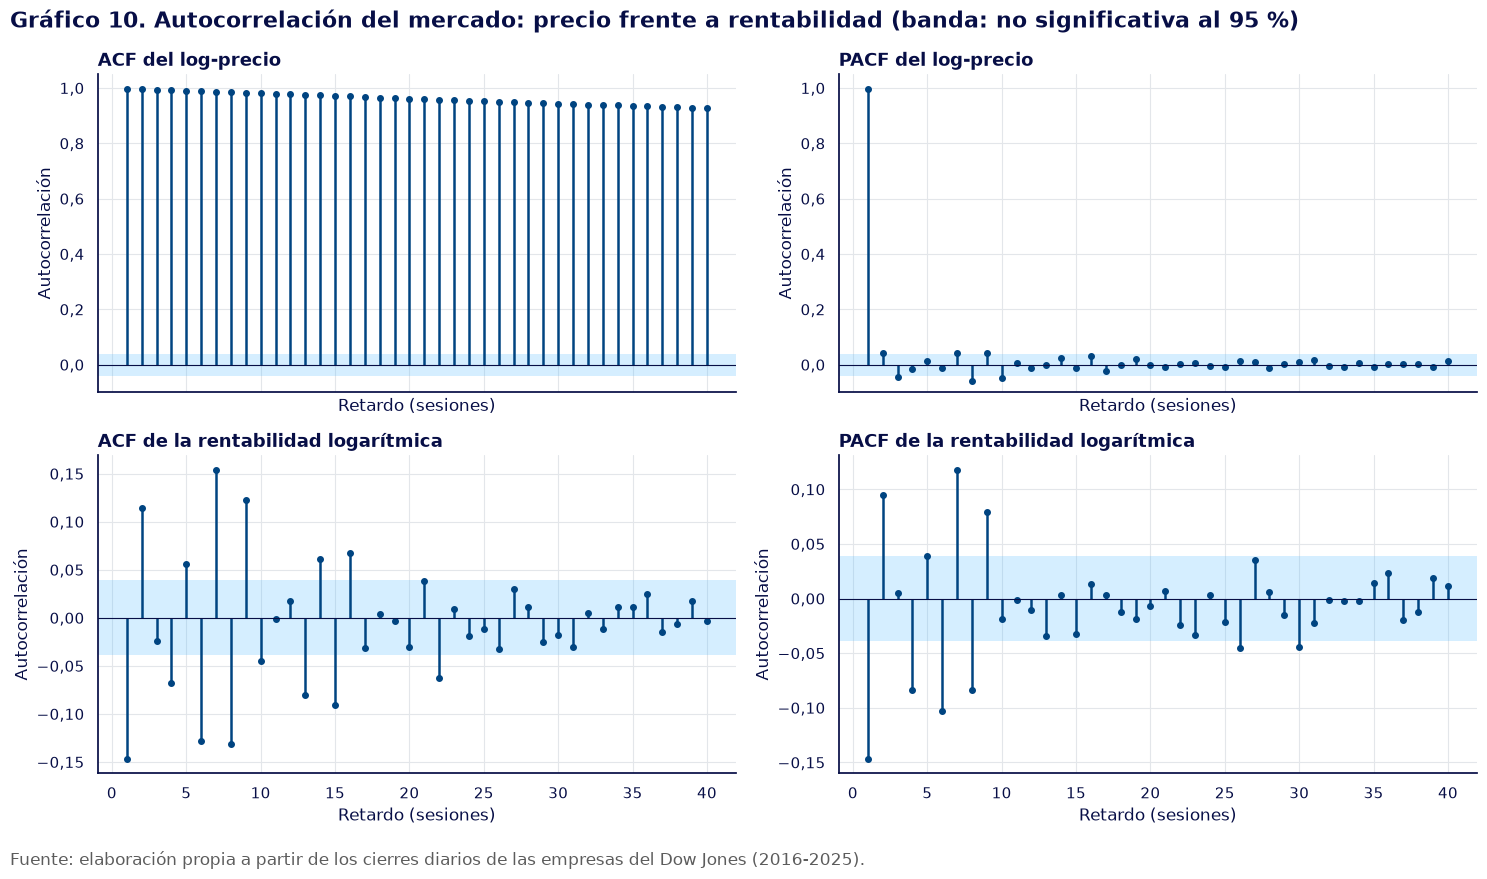

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_10_acf_pacf_mercado.png')

In [23]:
#Parámetros de esta sección
RETARDOS_ACF = 40                 #Retardos en los gráficos ACF / PACF

n = len(rent_mercado)
fig, ejes = plt.subplots(2, 2, figsize=(15, 8.5), sharex=True)
for fila, (serie, nombre) in enumerate([(log_mercado, "del log-precio"), (rent_mercado, "de la rentabilidad logarítmica")]):
    dibujar_correlograma(ejes[fila, 0], acf(serie.dropna(), nlags=RETARDOS_ACF, fft=True), n, f"ACF {nombre}")
    dibujar_correlograma(ejes[fila, 1], pacf(serie.dropna(), nlags=RETARDOS_ACF, method="ywm"), n, f"PACF {nombre}")
ejes[0, 0].set_ylim(-0.1, 1.05)
ejes[0, 1].set_ylim(-0.1, 1.05)
fig.suptitle("Gráfico 10. Autocorrelación del mercado: precio frente a rentabilidad (banda: no significativa al 95 %)",
             x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_10_acf_pacf_mercado", fuente=FUENTE)

ANÁLISIS:

La ACF del log-precio empieza en valores cercanos a 1 y decae muy lentamente (todavía es de 0,9 a 40 sesiones), y su PACF muestra un único pico en el retardo 1 prácticamente igual a 1, con el resto de retardos en torno a 0. Este patrón corresponde a un paseo aleatorio (un AR(1) con coeficiente 1, es decir, con raíz unitaria), por lo que el log-precio no es estacionario.

En la rentabilidad logarítmica, en cambio, las autocorrelaciones son pequeñas (como máximo de ±0,15) y a partir de unos 22 retardos quedan prácticamente dentro de la banda de no significación. No hay un decaimiento lento, por lo que la rentabilidad es compatible con una serie estacionaria. Los primeros retardos alternan de signo, lo que indica pequeños rebotes de un día a otro, que se recogen con el modelo ARMA. La estacionariedad de ambas series se confirma con los tests ADF y KPSS en la sección 7.

## Selección del modelo ARMA

ARMA(p, q) con p, q = 0, 1, 2 sobre la rentabilidad de cada empresa, elegido por AIC y BIC, y test de Ljung-Box sobre los residuos. La celda tarda uno o dos minutos.

In [24]:
#Parámetros de esta sección
ORDEN_MAX_ARMA = 2                #Se prueban ARMA(p, q) con p, q = 0..2

def seleccionar_arma(r, orden_max=ORDEN_MAX_ARMA):
    y = 100 * r.dropna().to_numpy()
    mejor = {"aic": (np.inf, None), "bic": (np.inf, None)}
    for p in range(orden_max + 1):
        for q in range(orden_max + 1):
            try:
                ajuste = ARIMA(y, order=(p, 0, q), trend="c").fit()
            except Exception:
                continue
            for criterio in ("aic", "bic"):
                valor = getattr(ajuste, criterio)
                if valor < mejor[criterio][0]:
                    mejor[criterio] = (valor, (p, q, ajuste))
    p_aic, q_aic, _ = mejor["aic"][1]
    p_bic, q_bic, ajuste_bic = mejor["bic"][1]
    residuos = pd.Series(np.asarray(ajuste_bic.resid) / 100, index=r.dropna().index)
    return {"arma_aic": f"({p_aic},{q_aic})", "arma_bic": f"({p_bic},{q_bic})", "p": p_bic, "q": q_bic,
            "p_ljungbox_residuos": p_ljung_box(residuos, grados_modelo=p_bic + q_bic)}, residuos


tabla_autocorrelacion, residuos_arma = {}, {}
for t in empresas + ["MERCADO"]:
    r = rent_mercado if t == "MERCADO" else rent_log[t]
    serie = r.dropna()
    valores_acf = acf(serie, nlags=20, fft=True)[1:]
    resultado, residuos_arma[t] = seleccionar_arma(serie)
    tabla_autocorrelacion[t] = {
        "acf_1": valores_acf[0],
        "retardos_signif_1_20": int((np.abs(valores_acf) > 1.96 / np.sqrt(len(serie))).sum()),
        "p_ljungbox_rent": p_ljung_box(serie),
        **resultado,
    }
tabla_autocorrelacion = pd.DataFrame(tabla_autocorrelacion).T
for c in ["acf_1", "p_ljungbox_rent", "p_ljungbox_residuos"]:
    tabla_autocorrelacion[c] = tabla_autocorrelacion[c].astype(float)
print(tabla_autocorrelacion.loc[orden_sector + ["MERCADO"]].round(3).to_string())
print(f"\nEmpresas con autocorrelación en la rentabilidad (Ljung-Box p < {ALFA}): "
      f"{(tabla_autocorrelacion.loc[empresas, 'p_ljungbox_rent'] < ALFA).sum()} de {N}")
print(f"Empresas cuyo ARMA elegido deja residuos sin autocorrelación (p > {ALFA}): "
      f"{(tabla_autocorrelacion.loc[empresas, 'p_ljungbox_residuos'] > ALFA).sum()} de {N}")

         acf_1 retardos_signif_1_20  p_ljungbox_rent arma_aic arma_bic  p  q  p_ljungbox_residuos
AAPL    -0.053                    5            0.000    (1,0)    (0,0)  0  0                0.000
CRM     -0.044                    5            0.000    (1,0)    (0,0)  0  0                0.000
CSCO    -0.095                    9            0.000    (1,0)    (1,0)  1  0                0.001
IBM     -0.038                    5            0.000    (2,2)    (2,2)  2  2                0.174
INTC    -0.075                    7            0.000    (2,2)    (0,2)  0  2                0.000
MSFT    -0.153                    8            0.000    (2,2)    (2,2)  2  2                0.000
AXP     -0.047                    7            0.000    (2,2)    (2,2)  2  2                0.000
GS      -0.045                    4            0.000    (2,2)    (2,2)  2  2                0.015
JPM     -0.095                   10            0.000    (2,2)    (2,2)  2  2                0.043
TRV     -0.155      

ANÁLISIS:

La rentabilidad presenta autocorrelación significativa en las 26 empresas según el test de Ljung-Box (p < 0,05), con entre 2 y 14 de los 20 primeros retardos fuera de la banda de significación. Sin embargo, es pequeña: la autocorrelación en el retardo 1 está entre −0,03 y −0,16 y es negativa en 24 de las 26 empresas, lo que indica pequeños rebotes de un día a otro con escaso poder predictivo.

El criterio BIC elige modelos sencillos en la mitad de las empresas (7 con ARMA(0,0) y 6 con AR(1)), mientras que el AIC tiende a elegir ARMA(2,2). Aun así, solo en 4 de las 26 empresas el modelo elegido deja residuos sin autocorrelación, lo que indica que la dependencia está repartida en muchos retardos pequeños y no se recoge con un ARMA de orden bajo. Además, el test de Ljung-Box supone varianza constante, por lo que parte de esta autocorrelación puede deberse a la heterocedasticidad de las rentabilidades, que se analiza en la sección 8.

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_11_orden_arma_bic.png


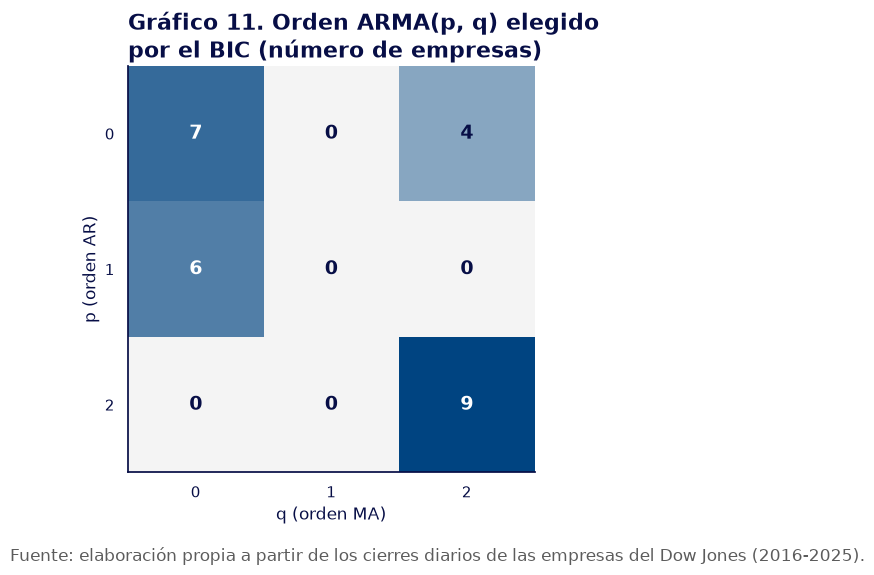

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_11_orden_arma_bic.png')

In [25]:
conteo_ordenes = (tabla_autocorrelacion.loc[empresas].groupby(["p", "q"]).size()
                  .unstack(fill_value=0).reindex(index=range(ORDEN_MAX_ARMA + 1), columns=range(ORDEN_MAX_ARMA + 1), fill_value=0))
maximo = max(conteo_ordenes.values.max(), 1)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(conteo_ordenes.values, cmap=CMAP_SECUENCIAL, vmin=0, vmax=maximo)
for i in range(conteo_ordenes.shape[0]):
    for j in range(conteo_ordenes.shape[1]):
        v = conteo_ordenes.values[i, j]
        ax.text(j, i, fmt_es(v), ha="center", va="center", fontsize=14, fontweight="bold",
                color=BLANCO if v > maximo / 2 else MARINO)
ax.set_xticks(range(ORDEN_MAX_ARMA + 1))
ax.set_yticks(range(ORDEN_MAX_ARMA + 1))
ax.set_xlabel("q (orden MA)")
ax.set_ylabel("p (orden AR)")
ax.grid(False)
ax.set_title("Gráfico 11. Orden ARMA(p, q) elegido\npor el BIC (número de empresas)")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_11_orden_arma_bic", fuente=FUENTE)

# 7. Estacionariedad

Media y desviación típica en tres tramos, y tests ADF (H₀: raíz unitaria) y KPSS (H₀: estacionaria) sobre el precio, el log-precio y la rentabilidad.

Log-precio del mercado:
             tramo 1 (2016-2019)  tramo 2 (2019-2022)  tramo 3 (2022-2025)
media                     4.8547               5.2913               5.5649
desv_tipica               0.1674               0.1534               0.1215

Rentabilidad logarítmica del mercado:
             tramo 1 (2016-2019)  tramo 2 (2019-2022)  tramo 3 (2022-2025)
media                    0.00060              0.00033              0.00048
desv_tipica              0.00839              0.01520              0.00932


Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_12_estacionariedad_tramos.png


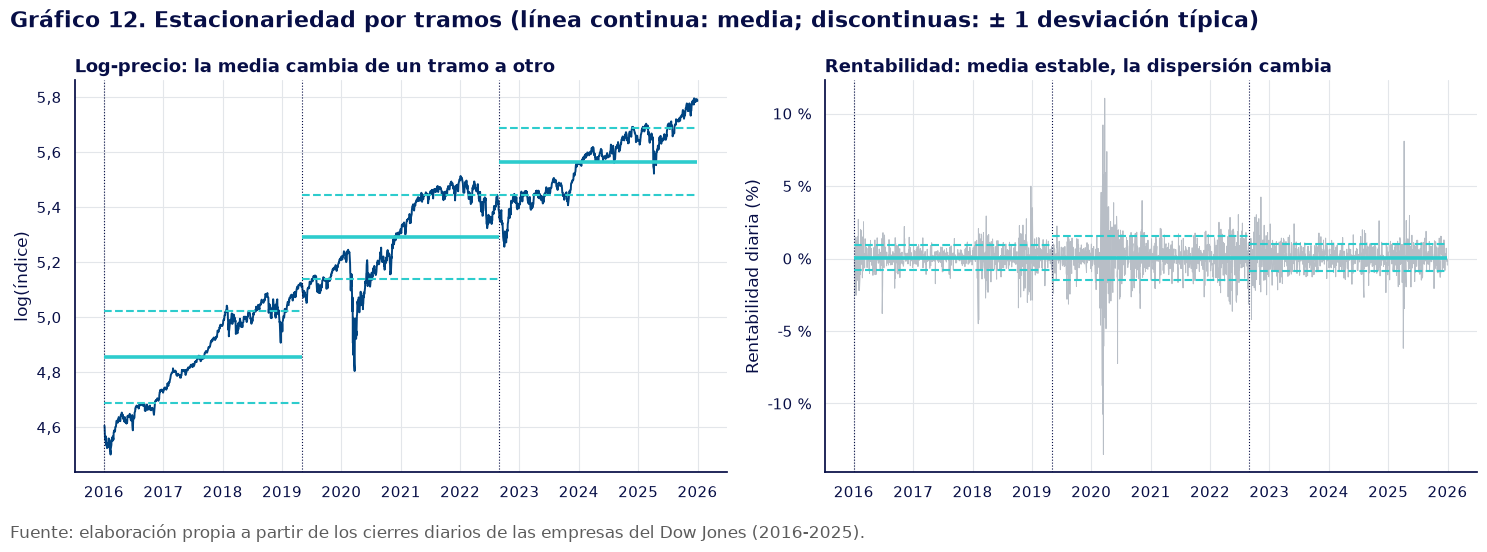

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_12_estacionariedad_tramos.png')

In [26]:
def partir_en_tramos(serie, tramos=3):
    """Divide la serie en `tramos` partes consecutivas de igual tamaño."""
    s = serie.dropna()
    cortes = np.linspace(0, len(s), tramos + 1).astype(int)
    return [s.iloc[cortes[i]:cortes[i + 1]] for i in range(tramos)]


def estadisticos_por_tramos(serie, tramos=3):
    partes = partir_en_tramos(serie, tramos)
    return pd.DataFrame({f"tramo {i + 1} ({p.index[0]:%Y}-{p.index[-1]:%Y})": {"media": p.mean(), "desv_tipica": p.std()}
                         for i, p in enumerate(partes)})


print("Log-precio del mercado:")
print(estadisticos_por_tramos(log_mercado).round(4).to_string())
print("\nRentabilidad logarítmica del mercado:")
print(estadisticos_por_tramos(rent_mercado).round(5).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, serie, titulo, color_serie, grosor, unidad in [
        (ejes[0], log_mercado, "Log-precio: la media cambia de un tramo a otro", PRINCIPAL, 1.4, "log(índice)"),
        (ejes[1], rent_mercado, "Rentabilidad: media estable, la dispersión cambia", GRIS, 0.7, "Rentabilidad diaria (%)")]:
    s = serie.dropna()
    ax.plot(s, color=color_serie, lw=grosor)
    for parte in partir_en_tramos(s, 3):
        m, d = parte.mean(), parte.std()
        ax.hlines(m, parte.index[0], parte.index[-1], color=AGUAMARINA, lw=2.6, zorder=3)
        ax.hlines([m - d, m + d], parte.index[0], parte.index[-1], color=AGUAMARINA, lw=1.5, ls="--", zorder=3)
        ax.axvline(parte.index[0], color=MARINO, lw=0.8, ls=":")
    eje_anios(ax)
    ax.set_ylabel(unidad)
    ax.set_title(titulo)
formato_eje_pct(ejes[1])
fig.suptitle("Gráfico 12. Estacionariedad por tramos (línea continua: media; discontinuas: ± 1 desviación típica)",
             x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_12_estacionariedad_tramos", fuente=FUENTE)

In [27]:
def test_estacionariedad(serie):
    s = serie.dropna()
    adf_estadistico, adf_p, _, _, adf_criticos, _ = adfuller(s, regression="c", autolag="AIC")
    kpss_estadistico, kpss_p, _, kpss_criticos = kpss(s, regression="ct", nlags="auto")
    adf_estacionaria, kpss_estacionaria = adf_p < ALFA, kpss_p > ALFA
    if adf_estacionaria and kpss_estacionaria:
        conclusion = "Estacionaria"
    elif not adf_estacionaria and not kpss_estacionaria:
        conclusion = "No estacionaria"
    elif kpss_estacionaria:
        conclusion = "Estacionaria en tendencia"
    else:
        conclusion = "Estacionaria en diferencias"
    return {"adf_estadistico": adf_estadistico, "adf_critico_5": adf_criticos["5%"], "adf_p": adf_p,
            "kpss_estadistico": kpss_estadistico, "kpss_critico_5": kpss_criticos["5%"], "kpss_p": kpss_p,
            "conclusion": conclusion}


filas = []
for t in empresas + ["MERCADO"]:
    for nombre, serie in [("precio", mercado if t == "MERCADO" else precios[t]),
                          ("log_precio", log_mercado if t == "MERCADO" else log_precios[t]),
                          ("rentabilidad", rent_mercado if t == "MERCADO" else rent_log[t])]:
        filas.append({"symbol": t, "serie": nombre, **test_estacionariedad(serie)})
tabla_estacionariedad = pd.DataFrame(filas).set_index(["symbol", "serie"])
print(tabla_estacionariedad.round(4).to_string())

                      adf_estadistico  adf_critico_5   adf_p  kpss_estadistico  kpss_critico_5  kpss_p                 conclusion
symbol  serie                                                                                                                    
AAPL    precio                 0.3191        -2.8627  0.9782            0.5879           0.146  0.0100            No estacionaria
        log_precio            -1.0146        -2.8627  0.7479            1.0267           0.146  0.0100            No estacionaria
        rentabilidad         -16.2211        -2.8627  0.0000            0.0407           0.146  0.1000               Estacionaria
AMGN    precio                -1.5292        -2.8627  0.5190            0.1340           0.146  0.0722  Estacionaria en tendencia
        log_precio            -1.6723        -2.8627  0.4454            0.1959           0.146  0.0175            No estacionaria
        rentabilidad         -16.2962        -2.8627  0.0000            0.0106           0

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_13_tests_adf_kpss.png


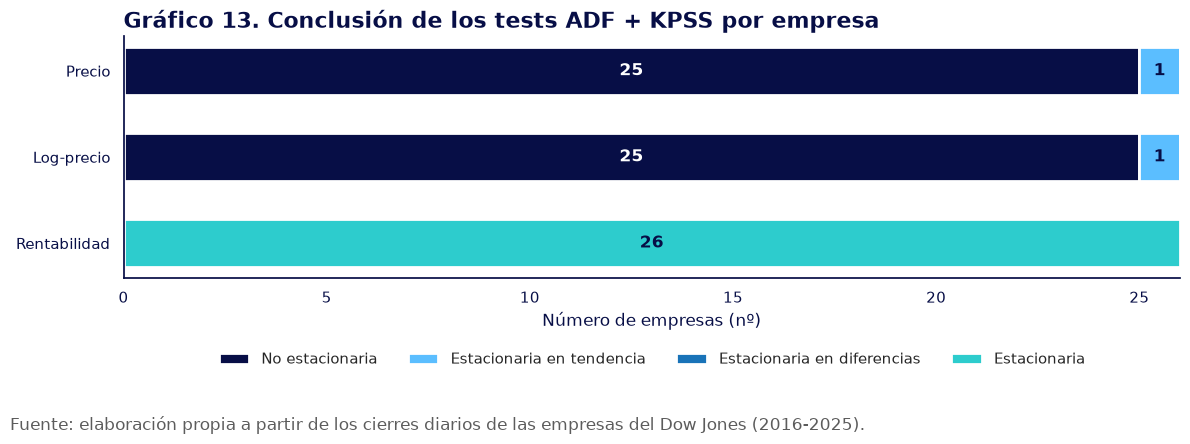

Orden de integración d (número de diferencias para que sea estacionaria): {1: 26}


In [28]:
resumen = (tabla_estacionariedad.drop("MERCADO", level="symbol").reset_index()
           .groupby(["serie", "conclusion"]).size().unstack(fill_value=0))
categorias = ["No estacionaria", "Estacionaria en tendencia", "Estacionaria en diferencias", "Estacionaria"]
color_barra = {"No estacionaria": MARINO, "Estacionaria en tendencia": CIELO,
               "Estacionaria en diferencias": MEDIO, "Estacionaria": AGUAMARINA}
color_texto = {"No estacionaria": BLANCO, "Estacionaria en tendencia": MARINO,
               "Estacionaria en diferencias": BLANCO, "Estacionaria": MARINO}
series_grafico = {"precio": "Precio", "log_precio": "Log-precio", "rentabilidad": "Rentabilidad"}
resumen = resumen.reindex(index=list(series_grafico), columns=categorias, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4.2))
izquierda = np.zeros(len(resumen))
for categoria in categorias:
    valores = resumen[categoria].to_numpy()
    ax.barh(list(series_grafico.values()), valores, left=izquierda, color=color_barra[categoria], height=0.55,
            edgecolor=BLANCO, linewidth=2, label=categoria)
    for i, v in enumerate(valores):
        if v > 0:
            ax.text(izquierda[i] + v / 2, i, fmt_es(v), ha="center", va="center", color=color_texto[categoria],
                    fontweight="bold")
    izquierda += valores
ax.invert_yaxis()
ax.set_xlim(0, N)
ax.set_xlabel("Número de empresas (nº)")
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4)
ax.set_title("Gráfico 13. Conclusión de los tests ADF + KPSS por empresa")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_13_tests_adf_kpss", fuente=FUENTE)

#Orden de integración d: número de diferencias necesarias para que el ADF rechace la raíz unitaria
orden_integracion = {}
for t in empresas:
    if tabla_estacionariedad.loc[(t, "log_precio"), "adf_p"] < ALFA:
        orden_integracion[t] = 0
    elif tabla_estacionariedad.loc[(t, "rentabilidad"), "adf_p"] < ALFA:
        orden_integracion[t] = 1
    else:
        orden_integracion[t] = 2
orden_integracion = pd.Series(orden_integracion, name="orden_integracion")
print("Orden de integración d (número de diferencias para que sea estacionaria):",
      orden_integracion.value_counts(dropna=False).to_dict())

ANÁLISIS:

**Tramos.** La media del log-precio del mercado sube de 4,85 a 5,29 y a 5,56 en los tres tramos, mucho más que su desviación típica dentro de cada tramo (0,12-0,17): no es estacionario. En la rentabilidad la media es casi igual en los tres (0,06 %, 0,03 % y 0,05 %), pero la desviación típica del tramo del COVID (1,52 %) casi dobla la de los otros dos (0,84 % y 0,93 %): la varianza cambia (sección 8).

**Precio y log-precio.** El ADF no rechaza la raíz unitaria en ninguna empresa: los estadísticos están entre −2,26 y 2,16 en el precio y entre −2,60 y −0,10 en el log-precio (p entre 0,09 y 0,95), todos por encima del valor crítico al 5 % (−2,86). El KPSS rechaza la estacionariedad del log-precio en 25 de 26 empresas; KO sale "estacionaria en tendencia" por muy poco (KPSS 0,143 frente a 0,146) y se trata como el resto.

**Rentabilidad.** El ADF rechaza la raíz unitaria en todas las empresas (estadísticos entre −11,2 y −21,1; p = 0,000) y el KPSS no rechaza la estacionariedad en ninguna (entre 0,011 y 0,132).

**Conclusión.** Las series de precios son I(1): con una diferencia, la rentabilidad logarítmica, pasan a ser estacionarias. Por eso la tendencia se elimina diferenciando.

# 8. Heterocedasticidad

Test de Engle (ARCH) sobre los residuos ARMA de cada empresa, antes y después de estandarizar la rentabilidad por la volatilidad EWMA (λ = 0,94).

In [29]:
def p_ljung_box(serie, retardos=RETARDOS_TEST, grados_modelo=0):
    """p-valor del test de Ljung-Box (vale para las versiones antiguas y nuevas de statsmodels)."""
    resultado = acorr_ljungbox(serie, lags=[retardos], model_df=grados_modelo)
    if isinstance(resultado, pd.DataFrame):
        return float(resultado["lb_pvalue"].iloc[0])
    return float(np.asarray(resultado[1])[0])

In [30]:
#Parámetros de esta sección
VENTANA_CORTA = 21               # ~1 mes de sesiones
LAMBDA_EWMA = 0.94                #Factor de decaimiento de la volatilidad EWMA

volatilidad_ewma = np.sqrt(rent_log.pow(2).ewm(alpha=1 - LAMBDA_EWMA, adjust=False).mean().shift(1))
volatilidad_ewma = volatilidad_ewma.where(rent_log.notna().cumsum() > VENTANA_CORTA)   # descartar el arranque
rent_estandarizada = rent_log / volatilidad_ewma

vol_ewma_mercado = np.sqrt(rent_mercado.pow(2).ewm(alpha=1 - LAMBDA_EWMA, adjust=False).mean().shift(1))
vol_ewma_mercado = vol_ewma_mercado.iloc[VENTANA_CORTA:]
z_estandarizada_mercado = (rent_mercado / vol_ewma_mercado).dropna()


def test_engle(serie):
    s = serie.dropna()
    lm, p_lm, _, _ = het_arch(s - s.mean(), RETARDOS_TEST)
    return lm, p_lm


tabla_heterocedasticidad = {}
for t in empresas + ["MERCADO"]:
    z = z_estandarizada_mercado if t == "MERCADO" else rent_estandarizada[t]
    lm_res, p_res = test_engle(residuos_arma[t])
    lm_z, p_z = test_engle(z)
    tabla_heterocedasticidad[t] = {"arch_lm_residuos": lm_res, "arch_p_residuos": p_res,
                                   "arch_lm_estandarizada": lm_z, "arch_p_estandarizada": p_z}
tabla_heterocedasticidad = pd.DataFrame(tabla_heterocedasticidad).T
print(tabla_heterocedasticidad.loc[orden_sector + ["MERCADO"]].round(4).to_string())
print(f"\nEmpresas con heterocedasticidad condicional (ARCH p < {ALFA}): "
      f"residuos ARMA {(tabla_heterocedasticidad.loc[empresas, 'arch_p_residuos'] < ALFA).sum()} de {N} | "
      f"rentabilidad estandarizada {(tabla_heterocedasticidad.loc[empresas, 'arch_p_estandarizada'] < ALFA).sum()} de {N}")

         arch_lm_residuos  arch_p_residuos  arch_lm_estandarizada  arch_p_estandarizada
AAPL             354.3263              0.0                 5.2294                0.8753
CRM               59.9654              0.0                 1.2110                0.9996
CSCO             245.6763              0.0                 4.2219                0.9368
IBM              163.3491              0.0                 2.2024                0.9945
INTC             100.0769              0.0                 2.4707                0.9913
MSFT             471.5962              0.0                 3.0455                0.9803
AXP              479.7852              0.0                 9.3593                0.4984
GS               617.4101              0.0                14.1279                0.1672
JPM              555.9105              0.0                10.2467                0.4191
TRV              489.5527              0.0                 1.9485                0.9967
V                537.2528       

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_14_heterocedasticidad.png


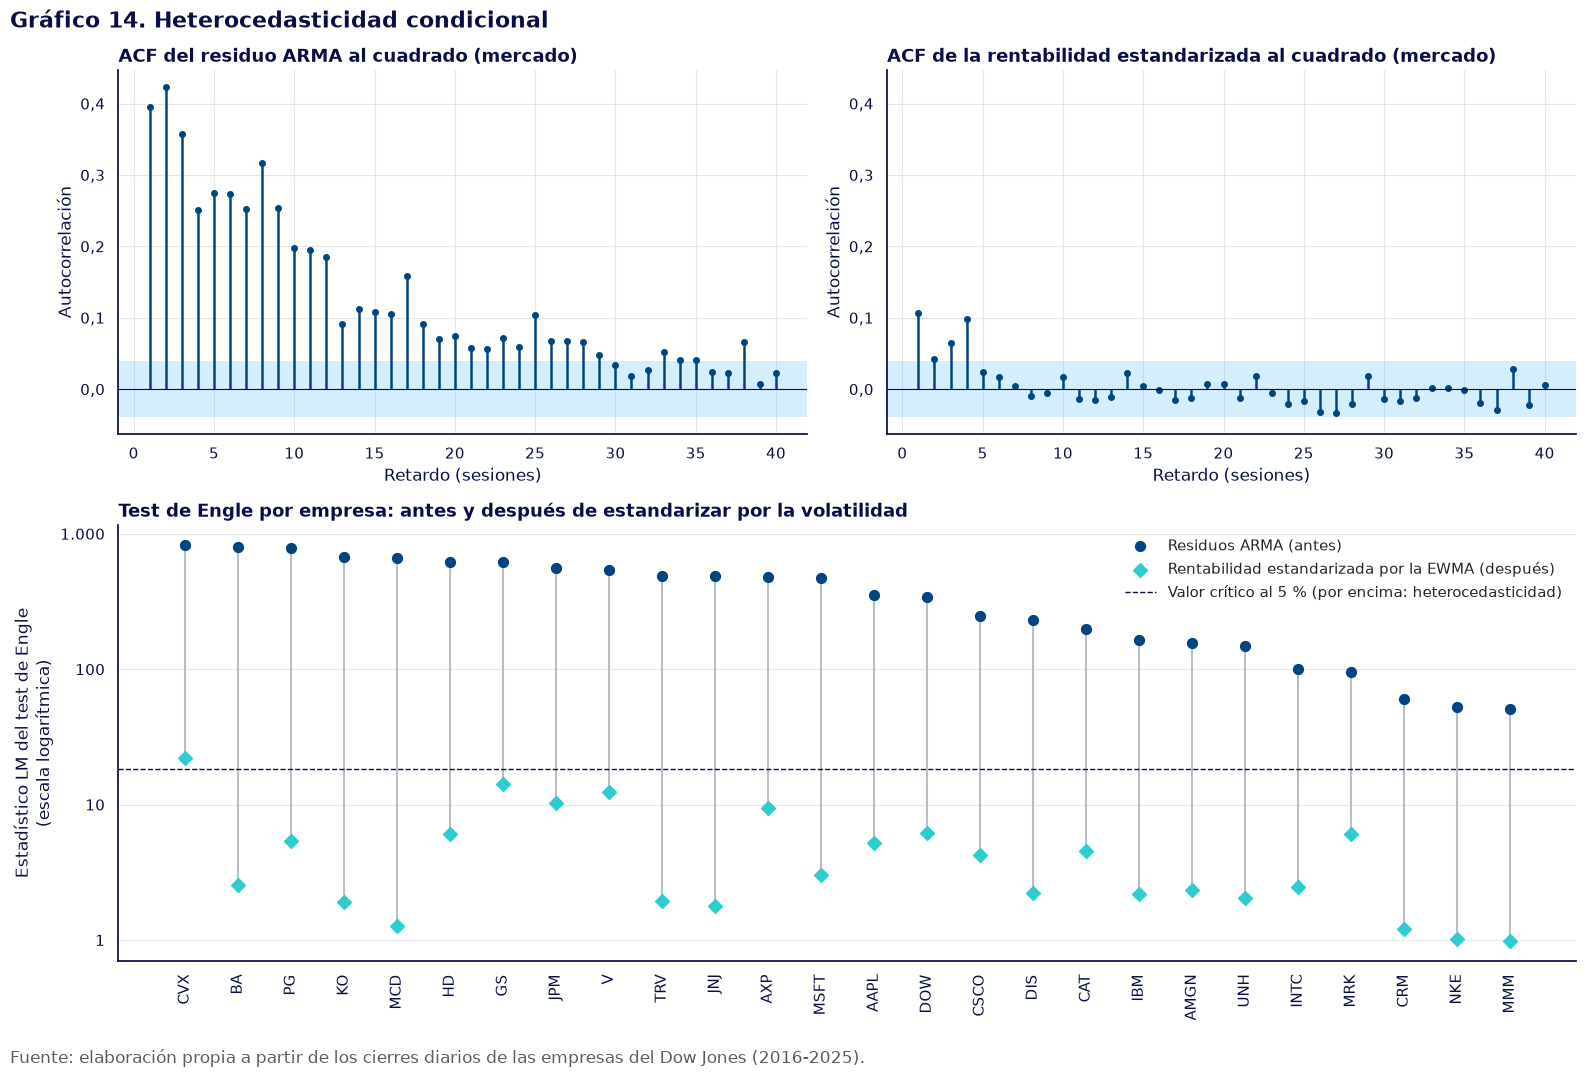

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_14_heterocedasticidad.png')

In [31]:
fig = plt.figure(figsize=(16, 10.5))
rejilla = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])
ax1 = fig.add_subplot(rejilla[0, 0])
ax2 = fig.add_subplot(rejilla[0, 1], sharey=ax1)
ax3 = fig.add_subplot(rejilla[1, :])

residuo_mercado = residuos_arma["MERCADO"]
dibujar_correlograma(ax1, acf((residuo_mercado - residuo_mercado.mean()) ** 2, nlags=RETARDOS_ACF, fft=True),
                     len(residuo_mercado), "ACF del residuo ARMA al cuadrado (mercado)")
dibujar_correlograma(ax2, acf((z_estandarizada_mercado - z_estandarizada_mercado.mean()) ** 2, nlags=RETARDOS_ACF, fft=True),
                     len(z_estandarizada_mercado), "ACF de la rentabilidad estandarizada al cuadrado (mercado)")

# Antes y después de estandarizar, unidos por una línea (puntos y no barras: el eje es logarítmico)
datos = tabla_heterocedasticidad.loc[empresas].sort_values("arch_lm_residuos", ascending=False)
x = np.arange(len(datos))
ax3.vlines(x, datos["arch_lm_estandarizada"], datos["arch_lm_residuos"], color=GRIS, lw=1.5, zorder=1)
ax3.scatter(x, datos["arch_lm_residuos"], s=50, color=PRINCIPAL, marker="o", zorder=2, label="Residuos ARMA (antes)")
ax3.scatter(x, datos["arch_lm_estandarizada"], s=50, color=AGUAMARINA, marker="D", zorder=2,
            label="Rentabilidad estandarizada por la EWMA (después)")
ax3.axhline(stats.chi2.ppf(1 - ALFA, RETARDOS_TEST), color=MARINO, lw=1, ls="--",
            label=f"Valor crítico al {pct_es(ALFA, 0)} (por encima: heterocedasticidad)")
ax3.set_xticks(x, datos.index, rotation=90)
ax3.set_yscale("log")
ax3.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt_es(v)))
ax3.yaxis.set_minor_formatter(mtick.NullFormatter())
ax3.set_ylabel("Estadístico LM del test de Engle\n(escala logarítmica)")
ax3.grid(axis="x", visible=False)
ax3.legend(loc="upper right")
ax3.set_title("Test de Engle por empresa: antes y después de estandarizar por la volatilidad")
fig.suptitle("Gráfico 14. Heterocedasticidad condicional", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_14_heterocedasticidad", fuente=FUENTE)

Test de Ljung-Box sobre la rentabilidad estandarizada, para ver si la autocorrelación de la sección 6 venía de la heterocedasticidad.

In [32]:
p_lb_estandarizada = pd.Series({t: p_ljung_box(rent_estandarizada[t].dropna()) for t in empresas})
print(f"Autocorrelación en la rentabilidad estandarizada (Ljung-Box p < {ALFA}): "
      f"{(p_lb_estandarizada < ALFA).sum()} de {N} (en la rentabilidad sin estandarizar: "
      f"{(tabla_autocorrelacion.loc[empresas, 'p_ljungbox_rent'] < ALFA).sum()} de {N})")

Autocorrelación en la rentabilidad estandarizada (Ljung-Box p < 0.05): 3 de 26 (en la rentabilidad sin estandarizar: 26 de 26)


ANÁLISIS:

**Antes de estandarizar.** La autocorrelación del residuo al cuadrado del mercado es de 0,40-0,42 en los dos primeros retardos y sigue siendo significativa hasta unos 30 retardos: hay clústeres de volatilidad. El test de Engle lo confirma en las 26 empresas (LM entre 51 y 828, frente a un valor crítico de 18,3; p = 0,000).

**Después de estandarizar.** La ACF queda casi dentro de la banda y el LM baja a valores entre 1 y 22: solo CVX sigue siendo significativa (LM = 22,2; p = 0,014), lo esperable por azar en 26 empresas. El índice del mercado sigue siendo heterocedástico (LM = 58,9; p = 0,000): su volatilidad común es más persistente de lo que recoge la EWMA.

**Autocorrelación tras estandarizar.** 3 de 26 empresas siguen teniendo autocorrelación, frente a las 26 de la sección 6.

**Conclusión.** La rentabilidad es estacionaria en media pero no en varianza. Para modelizar el riesgo hace falta un modelo GARCH; como aproximación se exporta la rentabilidad estandarizada por la EWMA.

# 9. Serie procesada y exportación

| Paso | Transformación | Motivo (sección) |
|---|---|---|
| 1 | Sesiones de mercado, sin rellenar festivos | Muestreo irregular (1) |
| 2 | Logaritmo del precio | La amplitud crece con el nivel (3) |
| 3 | Primera diferencia del log-precio = rentabilidad logarítmica | Tendencia estocástica, I(1) (2 y 7) |
| 4 | Sin desestacionalizar | No hay estacionalidad significativa (4) |
| 5 | Puntos de impacto marcados, no eliminados | Picos reales e imprevisibles (5) |
| 6 | Rentabilidad estandarizada por la volatilidad EWMA | Heterocedasticidad condicional (8) |

Guardado: /mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_15_serie_paso_a_paso.png


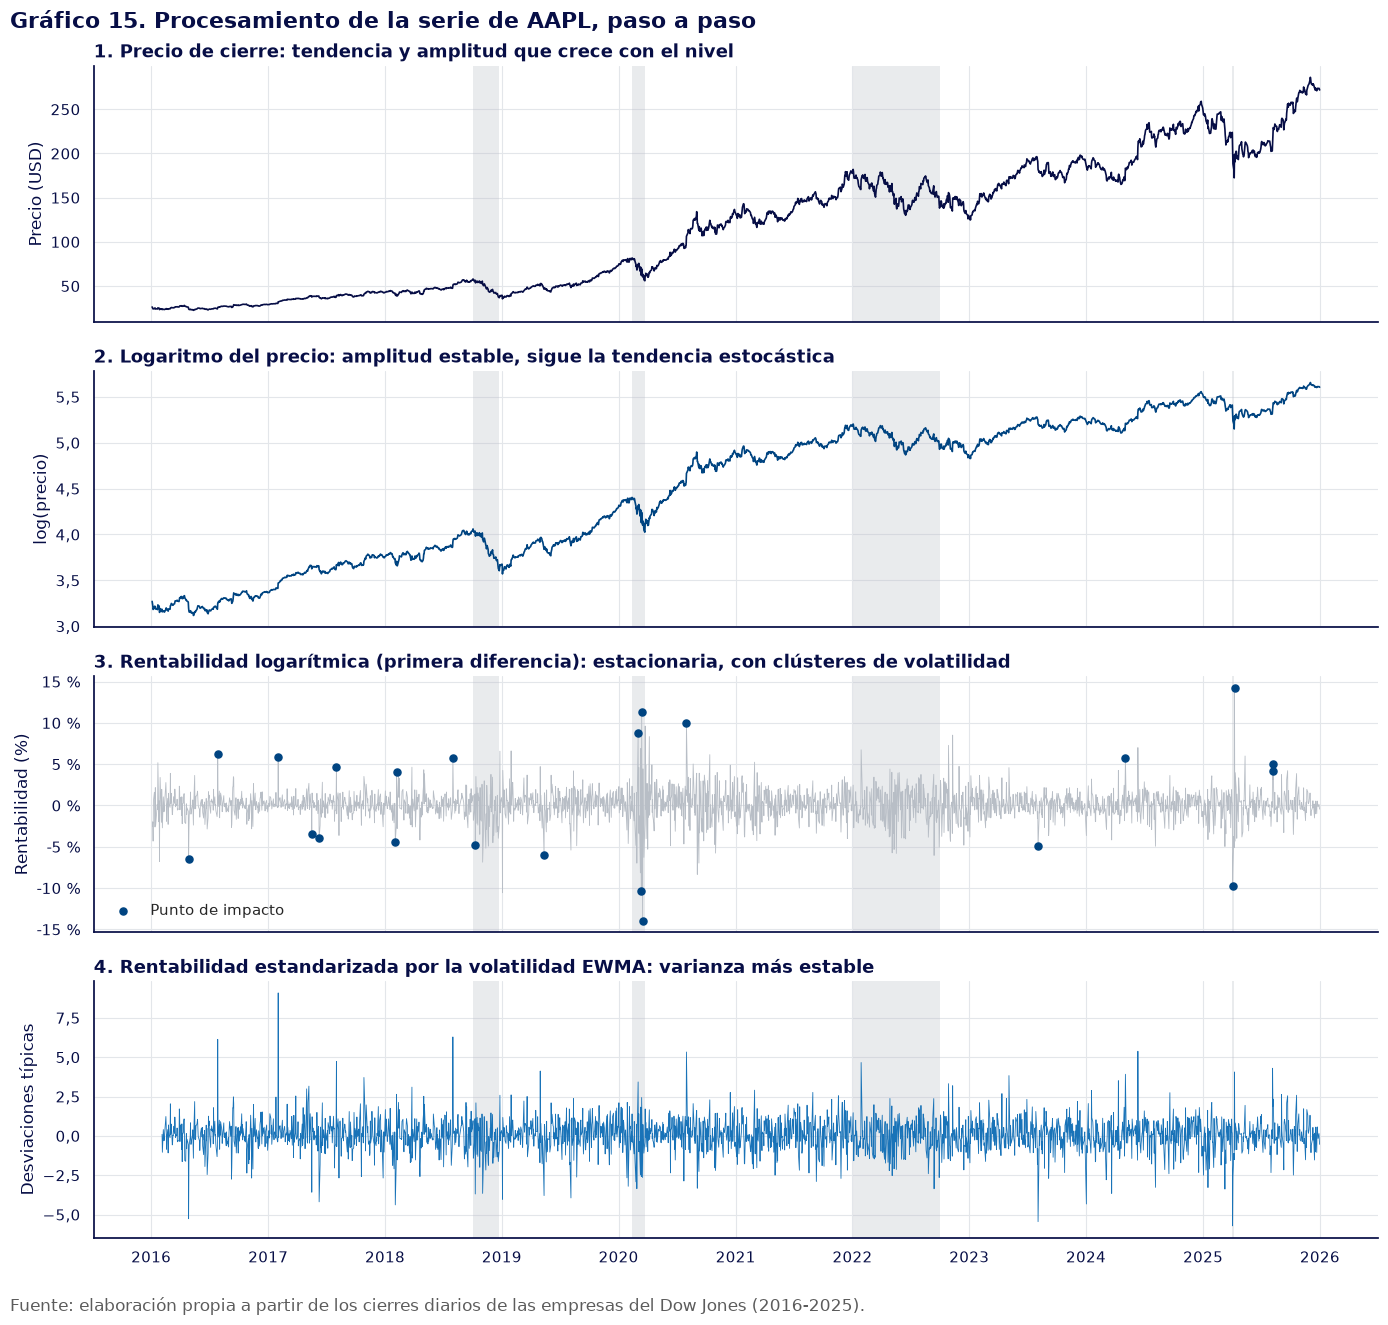

PosixPath('/mnt/windows/Users/danie/Desktop/MONDRAGON/3_BDA/RETOS/RETO09/26_27_R09_Azul_Claro/Graficos/procesamiento_15_serie_paso_a_paso.png')

In [33]:
t = EMPRESA_EJEMPLO
fig, ejes = plt.subplots(4, 1, figsize=(14, 13), sharex=True)
paneles = [
    (precios[t], "1. Precio de cierre: tendencia y amplitud que crece con el nivel", MARINO, 1.2, "Precio (USD)"),
    (log_precios[t], "2. Logaritmo del precio: amplitud estable, sigue la tendencia estocástica", PRINCIPAL, 1.2,
     "log(precio)"),
    (rent_log[t], "3. Rentabilidad logarítmica (primera diferencia): estacionaria, con clústeres de volatilidad",
     GRIS, 0.6, "Rentabilidad (%)"),
    (rent_estandarizada[t], "4. Rentabilidad estandarizada por la volatilidad EWMA: varianza más estable",
     MEDIO, 0.6, "Desviaciones típicas"),
]
for ax, (serie, titulo, col, grosor, unidad) in zip(ejes, paneles):
    sombrear_episodios(ax)
    ax.plot(serie, color=col, lw=grosor)
    ax.set_ylabel(unidad)
    ax.set_title(titulo)
picos = rent_log[t][impacto[t]]
ejes[2].scatter(picos.index, picos, s=26, color=PRINCIPAL, zorder=3, label="Punto de impacto")
ejes[2].legend(loc="lower left")
formato_eje_pct(ejes[2])
eje_anios(ejes[-1])
fig.suptitle(f"Gráfico 15. Procesamiento de la serie de {t}, paso a paso", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "procesamiento_15_serie_paso_a_paso", fuente=FUENTE)

In [34]:
#Serie procesada diaria
columnas = {"close": precios, "log_close": log_precios, "rent_log": rent_log, "vol_ewma": volatilidad_ewma,
            "rent_estandarizada": rent_estandarizada, "impacto": impacto}
series_procesadas = pd.concat(
    [tabla.rename_axis(index="date", columns="symbol").reset_index()
          .melt(id_vars="date", var_name="symbol", value_name=nombre).set_index(["date", "symbol"])
     for nombre, tabla in columnas.items()], axis=1)
series_procesadas = (series_procesadas.dropna(subset=["close"]).reset_index()
                     .sort_values(["symbol", "date"])[["symbol", "date", "close", "log_close", "rent_log",
                                                       "vol_ewma", "rent_estandarizada", "impacto"]])
series_procesadas["impacto"] = series_procesadas["impacto"].fillna(False).astype(bool)

# Tabla de propiedades por empresa
estac = tabla_estacionariedad.drop("MERCADO", level="symbol")
propiedades = pd.concat([
    tabla_tendencia[["mejor_tendencia", "crecimiento_anual_exp"]],
    tabla_estacional.loc[empresas],
    tabla_descomposicion[["rho_amplitud_nivel_precio", "descomposicion"]],
    tabla_impactos[["impactos_total", "impactos_mercado", "impactos_especificos"]],
    tabla_autocorrelacion.loc[empresas, ["acf_1", "p_ljungbox_rent", "arma_aic", "arma_bic", "p_ljungbox_residuos"]],
    estac.xs("precio", level="serie")[["adf_p", "kpss_p", "conclusion"]].add_prefix("precio_"),
    estac.xs("log_precio", level="serie")[["adf_p", "kpss_p", "conclusion"]].add_prefix("log_precio_"),
    estac.xs("rentabilidad", level="serie")[["adf_p", "kpss_p", "conclusion"]].add_prefix("rentabilidad_"),
    orden_integracion,
    tabla_heterocedasticidad.loc[empresas, ["arch_p_residuos", "arch_p_estandarizada"]],
], axis=1).loc[orden_sector]
propiedades.index.name = "symbol"
print(propiedades.round(3).to_string())

os.makedirs(RUTA_TRANSFORMADOS, exist_ok=True)
series_procesadas.to_csv(f"{RUTA_TRANSFORMADOS}/series_procesadas_diarias.csv", index=False)
propiedades.to_csv(f"{RUTA_TRANSFORMADOS}/propiedades_series.csv")
print(f"\nGuardado: series_procesadas_diarias.csv {series_procesadas.shape} | propiedades_series.csv {propiedades.shape}")

       mejor_tendencia  crecimiento_anual_exp  p_dia_semana  p_mes  acf_mensual_12  fuerza_tendencia  fuerza_estacionalidad  rho_amplitud_nivel_precio  descomposicion  impactos_total  impactos_mercado  impactos_especificos  acf_1  p_ljungbox_rent arma_aic arma_bic  p_ljungbox_residuos  precio_adf_p  precio_kpss_p          precio_conclusion  log_precio_adf_p  log_precio_kpss_p      log_precio_conclusion  rentabilidad_adf_p  rentabilidad_kpss_p rentabilidad_conclusion  orden_integracion  arch_p_residuos  arch_p_estandarizada
symbol                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 


Guardado: series_procesadas_diarias.csv (64557, 8) | propiedades_series.csv (26, 29)


ANÁLISIS:

El gráfico 15 resume el procesamiento con Apple. El precio se multiplica por diez (de unos 25 $ a unos 270 $) y sus oscilaciones crecen con el nivel; el logaritmo las estabiliza pero mantiene la tendencia. La rentabilidad oscila en torno a 0 sin tendencia, con clústeres de volatilidad en 2020, 2022 y abril de 2025, donde están los mayores puntos de impacto (hasta ±14 % en marzo de 2020). Al estandarizar por la EWMA desaparece el bloque de volatilidad de 2020, pero quedan picos aislados de 5 a 9 desviaciones típicas: las colas siguen siendo gruesas, así que un modelo GARCH debería usar una distribución con colas gruesas, como la t de Student.

# Conclusiones

1. **Frecuencia:** 26 empresas y 2.514 sesiones diarias con muestreo irregular (fines de semana y festivos) y sin huecos; solo DOW empieza más tarde (20/03/2019).
2. **Tendencia:** todas las series de precios tienen una tendencia marcada (F_T entre 0,80 y 0,99). Es estocástica, así que se elimina diferenciando.
3. **Descomposición:** 23 de 26 empresas son multiplicativas en precio; con el logaritmo pasan a ser aditivas.
4. **Estacionalidad y ciclo:** no hay estacionalidad (Kruskal-Wallis en el mercado p = 0,75 por día y p = 0,28 por mes; F_S entre 0,03 y 0,24). La componente cíclica no es periódica: responde a crisis concretas.
5. **Residuo e impactos:** 647 puntos de impacto (entre 9 y 35 por empresa), 226 de ellos en 17 días de impacto de mercado (febrero de 2018, febrero y marzo de 2020, abril de 2025 y el 24/06/2016). Se marcan, no se eliminan.
6. **Autocorrelación:** la rentabilidad tiene autocorrelación significativa pero pequeña (retardo 1 entre −0,16 y 0,05).
7. **Estacionariedad:** el precio y el log-precio no son estacionarios y la rentabilidad sí: las series son I(1).
8. **Heterocedasticidad:** presente en las 26 empresas; la EWMA la corrige en 25, pero no en el índice del mercado.